<div style='background-color: #0d2b45; padding: 32px; border-radius: 14px; border-left: 10px solid #2ec4b6;'>

  <h1 style='margin: 0; font-size: 2.2em; line-height: 1.25; color: #ffffff;'><b>🔍 DualLens Analytics — Trustworthy AI Investment Research</b></h1>
  <h2 style='margin: 14px 0 0 0; font-size: 1.25em; font-weight: 600; line-height: 1.4; color: #9ff0e6;'>Grounded RAG · LLM-as-Judge Evaluation · Self-Improving Prompts (DSPy + GEPA) · Confidence-Routed Decisions</h2>
  <p style='margin: 18px 0 0 0; font-size: 1.08em; line-height: 1.6; color: #ffffff;'>Build an AI research system that fuses live financial data with company strategy documents — and, unlike a naive chatbot, <b>measures</b> its own answer quality, <b>optimizes</b> its own prompt against a gold dataset, and <b>routes</b> its final recommendation by confidence so no untrusted answer ever reaches a client.</p>
</div>

**Submitted by:** Saba Azad  
**Program:** JHU Certificate Program in Agentic AI · Generative AI Foundations · Week 5, Project 1  
**Model used for all LLM roles:** `gpt-4o-mini`

## 🎯 **Learning Objectives**

By completing this notebook, you will be able to:

✅ **Fuse quantitative + qualitative data sources** — pull live market data with yfinance and combine it with insights retrieved from unstructured PDF reports.

✅ **Build a metadata-filtered RAG pipeline** — chunk, embed, and store documents in ChromaDB with company tags, so a question about MSFT never gets answered from GOOGL passages.

✅ **Diagnose retrieval separately from generation** — use a gold dataset to measure whether failures come from *fetching the wrong passages* or *answering badly from good passages*.

✅ **Design a 3-metric LLM-as-Judge harness** — score every answer on Groundedness, Context Relevance, and Answer Relevance with machine-readable rubrics, and cross-validate judges against an objective accuracy check.

✅ **Optimize prompts automatically with DSPy + GEPA** — recast the prompt as a typed `dspy.Signature`, drive GEPA with a deterministic gold-set metric, and prove the improvement on **held-out questions the optimizer never saw**.

✅ **Ship decisions with confidence routing** — aggregate evaluation signals into a confidence score and route the final investment ranking: client-ready / flagged / held for human review.

## 📊 **Marking Scheme (Total: 20 Marks)**

<div style='background-color: #fffaf3; color: #1f2933; padding: 18px 22px; border-radius: 10px; border: 2px solid #e67e22; font-size: 1.02em; line-height: 1.6;'>

### 📍 <font color="#a93226">**Part 1 — Core Pipeline (8 marks)**</font>
<font color="#1f2933">

- Financial lens — stock history + metrics DataFrame + visualizations — **2 marks**
- Narrative lens — PDF ingestion, chunking with company metadata, ChromaDB vector store — **2 marks**
- Grounded RAG function + 5-query typed test suite (incl. out-of-scope trap) — **3 marks**
- Retrieval diagnostics — gold-set hit-rate with vs. without the company filter — **1 mark**
</font>

### 📍 <font color="#a93226">**Part 2 — Evaluation (5 marks)**</font>
<font color="#1f2933">

- Three LLM-as-Judge rubrics (Groundedness, Context Relevance, Answer Relevance) + batch evaluation loop + pass/fail table — **3 marks**
- Objective gold-set accuracy check (`expected_substring`) + per-company breakdown + judge cross-validation — **2 marks**
</font>

### 📍 <font color="#a93226">**Part 3 — Optimization & Decision Layer (5 marks)**</font>
<font color="#1f2933">

- DSPy `Signature` + retrieval-aware `Module` + deterministic metric with feedback — **2 marks**
- GEPA compilation + evolved-prompt inspection + before/after comparison on the held-out test split — **2 marks**
- Fused ranking (financial + retrieved insights) + confidence score + routing verdict — **1 mark**
</font>

### 📍 <font color="#a93226">**Part 4 — Summary & Future Scope (2 marks)**</font>
<font color="#1f2933">

- Observations & learnings — **1 mark**
- Future scope (what would you build next?) — **1 mark**
</font>
</div>


---

### <font color="red"> **# Important Points To Note** </font>

1. For ALL LLM instances in this project (answerer, judges, DSPy task LM, GEPA reflection LM) use the **`"gpt-4o-mini"`** model only.
2. Look for cells marked **📝 YOUR TASK** — each gives you the function/class **skeleton** (names, signatures, docstrings, and step comments) with **`...` placeholders** where your code goes. Replace every `...` with your implementation; the skeleton tells you exactly what each piece must do.
3. **Do not rename** the skeleton's functions, classes, or variables — later **provided** cells depend on these exact names and will fail otherwise.
4. **💡 Hints** appear inside the trickier tasks. Cells without hints are expected to be within reach.
5. **Do not modify** the provided cells, the evaluation question set, the five typed test questions, or the gold-split parameters (`test_size=0.4`, `random_state=42`) — these keep your run comparable with the model solution released after submission.
6. For project submission, please provide the project in **HTML format.** Refer to the **"Guidelines: Converting IPYNB to HTML Files.pdf"** for instructions. Ensure all **outputs are clearly visible**, and enclose prompts in triple quotes **`"""`** so they remain fully visible after conversion.

---

## 📑 **Table of Contents**

1. [Introduction & Business Problem](#section1)
2. [System Architecture Overview](#section2)
3. [Environment Setup](#section3)
4. [Step 1 — Financial Lens: Market Data & Visualization](#section4)
5. [Step 2 — Narrative Lens: Document Ingestion & Vectorization](#section5)
6. [Step 3 — Grounded Q&A: The RAG Pipeline](#section6)
7. [Step 4 — Quality Control: LLM-as-Judge Evaluation](#section7)
8. [Step 5 — Self-Improvement: Prompt Optimization with DSPy + GEPA](#section8)
9. [Step 6 — Decision Layer: Fused Ranking + Confidence Routing](#section9)
10. [Step 7 — Summary & Future Scope](#section10)

## 📖 **Glossary**

Skim this once before reading the rest — the notebook uses these terms throughout.

<div style='background:#ffffff; border:2px solid #1f6f78; border-radius:10px; overflow:hidden; margin-top:14px; max-width:900px;'>
<div style='background:#1f6f78; color:#ffffff; font-size:17px; font-weight:700; padding:10px 16px;'>💼 Domain terms</div>
<table style='width:100%; border-collapse:collapse; margin:0; font-size:15px; line-height:1.55;'>
<tr><th style='background:#e3f2f1; color:#0d2b45; text-align:left; padding:8px 16px; width:24%; border-bottom:2px solid #1f6f78;'>Term</th><th style='background:#e3f2f1; color:#0d2b45; text-align:left; padding:8px 16px; border-bottom:2px solid #1f6f78;'>Meaning</th></tr>
<tr><td style='background:#ffffff; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Market Cap</td><td style='background:#ffffff; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Total market value of a company's outstanding shares.</td></tr>
<tr><td style='background:#f7f9fb; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>P/E Ratio</td><td style='background:#f7f9fb; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Price-to-Earnings — how much investors pay per dollar of earnings. High P/E = priced for growth.</td></tr>
<tr><td style='background:#ffffff; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Dividend Yield</td><td style='background:#ffffff; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Annual dividend income as a percentage of the stock price.</td></tr>
<tr><td style='background:#f7f9fb; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Beta</td><td style='background:#f7f9fb; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>A stock's volatility relative to the overall market (1.0 = moves with the market).</td></tr>
<tr><td style='background:#ffffff; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Grounding</td><td style='background:#ffffff; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Forcing every claim in an AI answer to trace back to a source document the firm has verified.</td></tr>
<tr><td style='background:#f7f9fb; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Hallucination</td><td style='background:#f7f9fb; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>A confident AI claim that does <b>not</b> exist in any source document — the failure that almost shipped to a DualLens client.</td></tr>
<tr><td style='background:#ffffff; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Gold dataset</td><td style='background:#ffffff; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'><code style='background:#e8edf3; color:#0d2b45; padding:1px 5px; border-radius:4px; font-size:0.92em;'>golden_retrieval.csv</code> — 20 questions with verified correct answers (<code style='background:#e8edf3; color:#0d2b45; padding:1px 5px; border-radius:4px; font-size:0.92em;'>expected_substring</code>) drawn from the source PDFs. Our objective measuring stick.</td></tr>
<tr><td style='background:#f7f9fb; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Confidence routing</td><td style='background:#f7f9fb; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Sending outputs down different paths based on measured quality: client-ready / flagged / held for human review.</td></tr>
</table></div>

<div style='background:#ffffff; border:2px solid #5b3a9e; border-radius:10px; overflow:hidden; margin-top:14px; max-width:900px;'>
<div style='background:#5b3a9e; color:#ffffff; font-size:17px; font-weight:700; padding:10px 16px;'>🧠 Technical terms</div>
<table style='width:100%; border-collapse:collapse; margin:0; font-size:15px; line-height:1.55;'>
<tr><th style='background:#ece6f7; color:#0d2b45; text-align:left; padding:8px 16px; width:24%; border-bottom:2px solid #5b3a9e;'>Term</th><th style='background:#ece6f7; color:#0d2b45; text-align:left; padding:8px 16px; border-bottom:2px solid #5b3a9e;'>Meaning</th></tr>
<tr><td style='background:#ffffff; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>RAG</td><td style='background:#ffffff; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Retrieval-Augmented Generation — fetch the most relevant document passages, then have the LLM answer <b>only</b> from them.</td></tr>
<tr><td style='background:#f7f9fb; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Chunk</td><td style='background:#f7f9fb; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>A small, overlapping slice of a document (~512 tokens here) — the unit that gets embedded and retrieved.</td></tr>
<tr><td style='background:#ffffff; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Embedding</td><td style='background:#ffffff; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>A numerical "fingerprint of meaning" for a chunk of text. Similar meanings → nearby vectors.</td></tr>
<tr><td style='background:#f7f9fb; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Vector store</td><td style='background:#f7f9fb; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>A database (ChromaDB here) that finds chunks whose embeddings are most similar to a question's embedding.</td></tr>
<tr><td style='background:#ffffff; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Metadata filter</td><td style='background:#ffffff; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Restricting retrieval to chunks tagged with a specific company — our fix for cross-company contamination.</td></tr>
<tr><td style='background:#f7f9fb; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>LLM-as-Judge</td><td style='background:#f7f9fb; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Using an LLM with a scoring rubric to grade another LLM's output (1–5 here, with a machine-readable <code style='background:#e8edf3; color:#0d2b45; padding:1px 5px; border-radius:4px; font-size:0.92em;'>Score: N</code> line).</td></tr>
<tr><td style='background:#ffffff; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Groundedness</td><td style='background:#ffffff; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Judge metric: are the answer's claims actually supported by the retrieved context?</td></tr>
<tr><td style='background:#f7f9fb; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Context Relevance</td><td style='background:#f7f9fb; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Judge metric: did the <b>retriever</b> fetch passages that can answer the question? (Evaluates retrieval, not generation.)</td></tr>
<tr><td style='background:#ffffff; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Answer Relevance</td><td style='background:#ffffff; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Judge metric: does the answer actually address what was asked?</td></tr>
<tr><td style='background:#f7f9fb; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>DSPy Signature</td><td style='background:#f7f9fb; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>A typed prompt contract — the docstring <i>is</i> the prompt, and inputs/outputs are declared fields.</td></tr>
<tr><td style='background:#ffffff; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>GEPA</td><td style='background:#ffffff; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>A reflection-based prompt optimizer: score candidates → read failure feedback → rewrite the prompt → keep the winners → repeat.</td></tr>
<tr><td style='background:#f7f9fb; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Reflection LM</td><td style='background:#f7f9fb; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>The model inside GEPA that reads the metric's feedback and proposes the next prompt rewrite.</td></tr>
<tr><td style='background:#ffffff; color:#0d2b45; font-weight:700; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Train/test split</td><td style='background:#ffffff; color:#1f2933; padding:9px 16px; vertical-align:top; border-top:1px solid #dde3ea;'>Letting the optimizer learn from one slice of the gold set (12 questions) and proving generalization on a hidden slice (8 questions).</td></tr>
</table></div>

<a name='section1'></a>
## 1️⃣ **Introduction & Business Problem**

### 💼 **The Challenge**

**DualLens Analytics** is a boutique investment research firm. Its analysts answer one deceptively simple question for clients: *"Which technology companies are worth investing in right now?"*

Answering it well requires two lenses at once:

- **The numbers lens** — stock trends, market capitalization, revenue, valuation ratios. Structured, abundant, easy to chart.
- **The narrative lens** — what a company is actually *building* for the future, especially its AI initiatives. This lives in long strategy reports: unstructured, dense, slow to read.

Until recently the narrative lens was manual: 10–12 analyst-hours per company, per refresh, across a five-company universe (**GOOGL, MSFT, IBM, NVDA, AMZN**).

Six months ago the firm piloted an AI assistant — paste the documents into an LLM, ask questions, get answers. It was fast, and it became a liability. In a client-facing report the assistant confidently described an NVDA project timeline **that didn't exist in any source document**. A senior analyst caught it two hours before the report shipped. An internal audit found the same pattern repeatedly:

- Answers that mixed up **which company** a project belonged to
- **Fabricated specifics** (dates, dollar figures) not present in any document
- **No way to tell** a reliable answer from an unreliable one — every answer *sounded* equally confident

The firm's conclusion: the problem was never getting an AI to produce answers. The problem is producing answers you can **trust, measure, and improve**.

### 💡 **The Solution**

**DualLens 2.0** — a RAG system with a built-in quality-control layer and a self-improving prompt:

1. **Grounds every answer in source documents** — retrieval + a strict "answer only from context, else say *I don't know*" contract.
2. **Measures answer quality automatically** — an LLM judge scores every answer on three dimensions, cross-checked against an objective gold dataset.
3. **Improves its own prompt** — GEPA reads failure feedback and rewrites the prompt, with the improvement *proven* on questions the optimizer never saw.
4. **Routes outputs by confidence** — the final investment ranking carries a confidence score; low-confidence outputs are held for human review, never silently trusted.

### 💸 **Cost of Inaction**

One shipped hallucination in a client report risks regulatory scrutiny and the firm's reputation. Reverting to manual reading means the research desk simply cannot scale beyond five companies. The system below is what turns analysts from *document readers* into *reviewers of flagged outputs*.

<a name='section2'></a>
## 2️⃣ **System Architecture Overview**

### 🏗️ **The Evaluation-Driven Pipeline**

Unlike the failed pilot — which generated answers and stopped — every generation stage here is paired with a measurement stage, and the measurements feed back into improving the system.

<div style='background:#f4f7fa; border:1px solid #cfd8e3; border-radius:12px; padding:18px; max-width:860px; font-family:-apple-system, Segoe UI, Roboto, Helvetica, Arial, sans-serif;'>
<div style='display:flex; gap:18px; align-items:stretch;'>
<div style='flex:1; display:flex; flex-direction:column;'>
<div style='background:#ffffff; color:#1f2933; border:2px solid #1f77b4; border-left:8px solid #1f77b4; border-radius:10px; padding:10px 14px; font-size:14.5px; line-height:1.45;'><div style='font-size:12px; font-weight:700; letter-spacing:0.06em; color:#1f77b4;'>STEP 1</div><div style='font-size:16px; font-weight:700; margin:2px 0 4px 0; color:#0d2b45;'>📈 Financial Lens</div><div style='color:#333f4d;'>yfinance → price charts<br>+ metrics table</div></div>
<div style='flex:1; display:flex; justify-content:center;'><div style='width:4px; background:#1f77b4; border-radius:2px;'></div></div>
<div style='text-align:center; font-size:13px; font-weight:600; color:#5a6b7b;'>numbers lens</div>
</div>
<div style='flex:1.25;'>
<div style='background:#ffffff; color:#1f2933; border:2px solid #1f6f78; border-left:8px solid #1f6f78; border-radius:10px; padding:10px 14px; font-size:14.5px; line-height:1.45;'><div style='font-size:12px; font-weight:700; letter-spacing:0.06em; color:#1f6f78;'>STEP 2</div><div style='font-size:16px; font-weight:700; margin:2px 0 4px 0; color:#0d2b45;'>📄 Narrative Lens</div><div style='color:#333f4d;'>PDFs → chunks → ChromaDB<br>(+ company metadata)</div></div>
<div style='text-align:center; font-size:22px; font-weight:700; color:#1f6f78; line-height:1.3;'>▼</div>
<div style='background:#ffffff; color:#1f2933; border:2px solid #1f6f78; border-left:8px solid #1f6f78; border-radius:10px; padding:10px 14px; font-size:14.5px; line-height:1.45;'><div style='font-size:12px; font-weight:700; letter-spacing:0.06em; color:#1f6f78;'>STEP 3</div><div style='font-size:16px; font-weight:700; margin:2px 0 4px 0; color:#0d2b45;'>💬 Grounded RAG Q&amp;A</div><div style='color:#333f4d;'>company-filtered retrieval<br>+ strict-context prompt</div></div>
<div style='text-align:center; font-size:22px; font-weight:700; color:#1f6f78; line-height:1.3;'>▼</div>
<div style='background:#ffffff; color:#1f2933; border:2px solid #c0392b; border-left:8px solid #c0392b; border-radius:10px; padding:10px 14px; font-size:14.5px; line-height:1.45;'><div style='font-size:12px; font-weight:700; letter-spacing:0.06em; color:#c0392b;'>STEP 4</div><div style='font-size:16px; font-weight:700; margin:2px 0 4px 0; color:#0d2b45;'>⚖️ Quality Control</div><div style='color:#333f4d;'>3 LLM-judge metrics<br>+ gold-set objective accuracy</div></div>
<div style='text-align:center; font-size:22px; font-weight:700; color:#1f6f78; line-height:1.3;'>▼ <span style='font-size:13px; font-weight:600; color:#5a6b7b;'>failure feedback</span></div>
<div style='background:#ffffff; color:#1f2933; border:2px solid #7d3c98; border-left:8px solid #7d3c98; border-radius:10px; padding:10px 14px; font-size:14.5px; line-height:1.45;'><div style='font-size:12px; font-weight:700; letter-spacing:0.06em; color:#7d3c98;'>STEP 5</div><div style='font-size:16px; font-weight:700; margin:2px 0 4px 0; color:#0d2b45;'>🧬 Self-Improvement</div><div style='color:#333f4d;'>DSPy + GEPA prompt optimization<br>(train on 12, prove on held-out 8)</div></div>
<div style='text-align:center; font-size:22px; font-weight:700; color:#1f6f78; line-height:1.3;'>▼ <span style='font-size:13px; font-weight:600; color:#5a6b7b;'>optimized RAG</span></div>
</div>
</div>
<div style='text-align:center; font-size:22px; font-weight:700; color:#1f6f78; line-height:1.3;'>▼ <span style='font-size:13px; font-weight:600; color:#5a6b7b;'>both lenses fused</span></div>
<div style='background:#0d2b45; color:#ffffff; border-radius:10px; padding:12px 16px; font-size:14.5px; line-height:1.45;'>
<div style='font-size:12px; font-weight:700; letter-spacing:0.06em; color:#9ff0e6;'>STEP 6</div>
<div style='font-size:16px; font-weight:700; margin:2px 0 8px 0; color:#ffffff;'>🎯 Fused Ranking + Confidence Score → Routing</div>
<div style='display:flex; gap:10px; flex-wrap:wrap;'>
<span style='background:#d4efdf; color:#145a32; font-weight:700; padding:5px 12px; border-radius:6px;'>✅ client-ready</span>
<span style='background:#fdebd0; color:#7e5109; font-weight:700; padding:5px 12px; border-radius:6px;'>⚠️ flagged</span>
<span style='background:#fadbd8; color:#78281f; font-weight:700; padding:5px 12px; border-radius:6px;'>🛑 held for human review</span>
</div>
</div>
</div>

### 🤖 **Cast of Characters (all `gpt-4o-mini`)**

| Role | Job | Settings |
|---|---|---|
| **Answerer LLM** | Generates grounded answers from retrieved context | `temperature=0` (deterministic) |
| **Judge LLM** | Scores answers on the three 1–5 rubrics | `temperature=0`, separate object from the answerer |
| **Task LM (DSPy)** | Runs candidate prompts during GEPA compilation | `temperature=0.1` |
| **Reflection LM (GEPA)** | Reads failure feedback, proposes prompt rewrites | `temperature=1.0` — creative variation helps reflection |

> 💰 **Single-model cost note.** A production setup would typically use a *stronger* model as judge/reflector. We run everything on `gpt-4o-mini` to keep costs minimal — and the design choice that makes this viable is the **deterministic gold-set metric** in Step 5: the optimization loop is scored by free Python (substring checks), not by noisy small-model judge calls. This trade-off is itself a real-world lesson.

### 🔁 **Logical Flow**

1. Build both lenses (Steps 1–2) → 2. Answer questions with grounded RAG (Step 3) → 3. Measure quality with judges + the gold dataset (Step 4) → 4. Let GEPA optimize the prompt against the gold-set metric and prove it generalizes (Step 5) → 5. Fuse both lenses into a ranked recommendation, score its confidence, and route it (Step 6).

<a name='section3'></a>
## 3️⃣ **Environment Setup**

### 3.1 · Install dependencies

In [54]:
# Installing the Libraries
!pip install -q --upgrade \
    "langchain>=1.0,<2.0" \
    "langchain-core>=1.0,<2.0" \
    "langchain-community>=0.4.2" \
    "langchain-openai>=0.3.0" \
    "langchain-chroma>=0.2.0" \
    "langchain-text-splitters>=0.3.0" \
    "chromadb>=0.5.0" \
    "pypdf>=4.0.0" \
    "openai>=1.40.0" \
    "tiktoken>=0.7.0" \
    "dspy==3.2.1" \
    "scikit-learn>=1.4" \
    "yfinance>=0.2.40"
print("### Library Installation - Done")

### Library Installation - Done


**Note:** Messages above may appear as errors, but they can be safely ignored. They are caused by minor dependency mismatches in optional packages and do not affect the functionality of this notebook.

### After installation, please **restart the runtime** and **do not re-run the above cell**. Continue execution from the next cell below.

### 3.2 · Load your OpenAI API key

- The `config.json` file should contain the **API_KEY** and **API BASE URL** provided for your account.
- Refer to the **OpenAI Access Token documentation** for how to generate and manage your API keys.
- The `config.json` should look like this:

```
{
    "API_KEY": "your_openai_api_key_here",
    "OPENAI_API_BASE": "https://your_openai_api_base/v1"
}
```

In [55]:
!ls /content

Companies-AI-Initiatives  golden_retrieval.csv	 sample_data
config.json		  Project_Datafiles.zip


In [56]:
# Load the `config.json` file and extract API key + base URL
import json
import os

file_name = 'config.json'
with open(file_name, 'r') as file:
    config = json.load(file)
    os.environ['OPENAI_API_KEY'] = config.get("API_KEY")           # Loading the API Key
    os.environ["OPENAI_BASE_URL"] = config.get("OPENAI_API_BASE")  # Loading the API Base URL

print("API credentials loaded into the environment.")

API credentials loaded into the environment.


In [57]:
# Quick connectivity check — confirms the key + base URL actually reach a working endpoint
from openai import OpenAI

_client = OpenAI()
_ping = _client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[{"role": "user", "content": "Reply with exactly: OK"}],
    max_tokens=5,
)
print("Connectivity check:", _ping.choices[0].message.content)

Connectivity check: OK


### 3.3 · Configuration & shared imports

One place for every knob the notebook uses. If you change a model or a retrieval depth, change it here.

In [58]:
# Core imports used across the notebook.
import warnings
warnings.filterwarnings('ignore')

import re
import time
import zipfile
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate

pd.set_option("display.max_colwidth", 120)

# Crisp, readable charts: high-resolution rendering + larger fonts and lines.
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "lines.linewidth": 2,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [59]:
# ---- Models ----------------------------------------------------------
# Single-model setup: gpt-4o-mini everywhere (see the cost note in Section 2).
MODEL_NAME      = "gpt-4o-mini"
EMBEDDING_MODEL = "text-embedding-3-small"

# ---- Companies under coverage ----------------------------------------
COMPANIES = ["GOOGL", "MSFT", "IBM", "NVDA", "AMZN"]

# ---- Retrieval & chunking knobs --------------------------------------
CHUNK_SIZE    = 512   # tokens per chunk (token-based splitting matches what models actually count)
CHUNK_OVERLAP = 64    # tokens shared between neighbouring chunks, so facts at boundaries aren't cut in half
TOP_K         = 4     # chunks retrieved per question

# ---- Evaluation & routing policy --------------------------------------
PASS_THRESHOLD       = 4      # a judge metric "passes" at >= 4 out of 5
CONF_CLIENT_READY    = 80     # confidence >= 80  -> ✅ client-ready
CONF_FLAGGED         = 60     # 60 <= conf < 80   -> ⚠️ flagged for awareness
                              # conf < 60         -> 🛑 held for human review

# ---- LLM objects -------------------------------------------------------
# Answerer — generates the RAG response. temperature=0 keeps answers stable
# and grounded; max_tokens caps response length.
llm = ChatOpenAI(model=MODEL_NAME, temperature=0, max_tokens=1024)

# Judge — a SEPARATE object so the evaluation role is explicit. In production
# this would be a stronger model; here it shares gpt-4o-mini for cost, which
# is exactly why Step 4 cross-validates the judges against the gold dataset.
judge_llm = ChatOpenAI(model=MODEL_NAME, temperature=0, max_tokens=600)

print(f"Configured: answerer={MODEL_NAME}, judge={MODEL_NAME}, embeddings={EMBEDDING_MODEL}")

Configured: answerer=gpt-4o-mini, judge=gpt-4o-mini, embeddings=text-embedding-3-small


<a name='section4'></a>
## 4️⃣ **Step 1 — Financial Lens: Market Data & Visualization**

The quantitative half of DualLens. We pull three years of price history plus five headline financial metrics for the coverage universe, and visualize them. These numbers feed the fused ranking in Step 6.

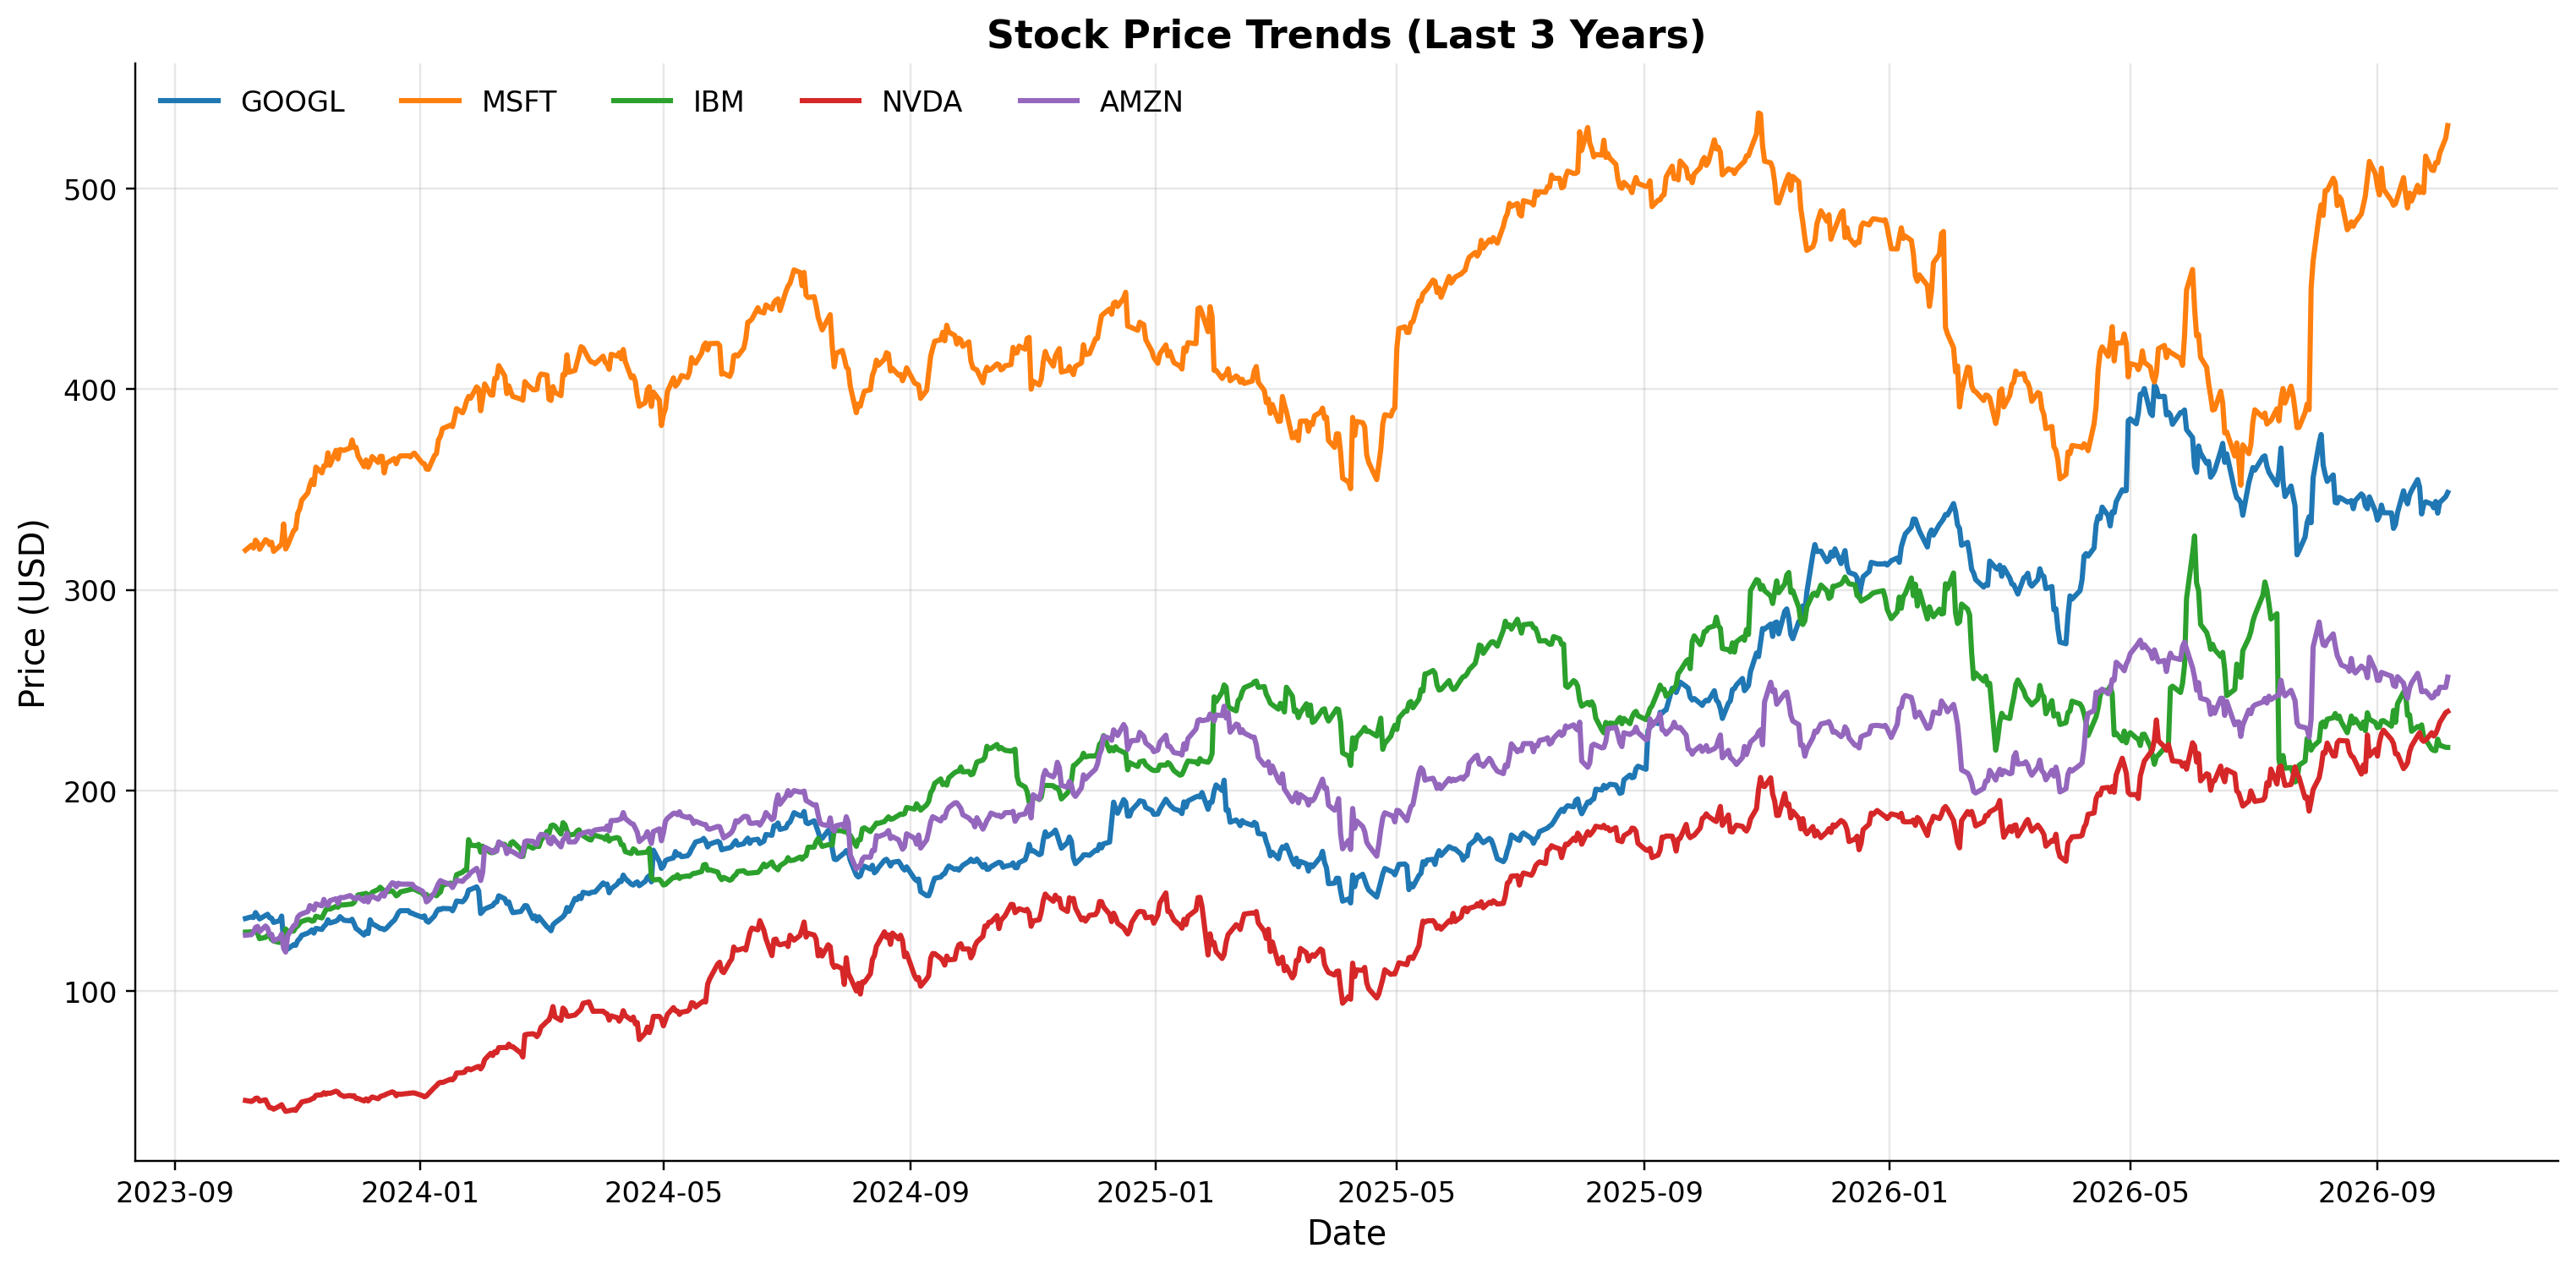

In [60]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Three-year price trend chart
# ═══════════════════════════════════════════════════════════════════════════
# One shared figure: the 3-year closing-price trend of all five companies.
# Replace each `...` below.
# ───────────────────────────────────────────────────────────────────────────
plt.figure(figsize=(14, 7))

for symbol in COMPANIES:
    ticker = yf.Ticker(symbol)
    data = ticker.history(period="3y")  # My CODE: fetch this ticker's daily history for the last 3 years
    plt.plot(data.index, data["Close"], label=symbol) # My CODE: plot the 'Close' series for this company, labelled with its symbol

plt.title("Stock Price Trends (Last 3 Years)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend(frameon=False, ncol=5, loc="upper left")
plt.tight_layout()
plt.show()

#### 💹 Financial Metrics

1. **Market Cap** — total market value of a company's outstanding shares.
2. **P/E Ratio** — how much investors are willing to pay per dollar of earnings.
3. **Dividend Yield** — annual dividend income as a percentage of the stock price.
4. **Beta** — a stock's volatility relative to the overall market.
5. **Total Revenue** — total income generated from business operations.

In [61]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Financial metrics DataFrame
# ═══════════════════════════════════════════════════════════════════════════
# Fetch the five headline metrics per company into `fin_df`.
# "Market Cap" is done for you as the worked example — complete the other four.
# 💡 Hint: explore ticker.info's keys; use .get(key, 0) since some companies
#          don't report every field.
# ───────────────────────────────────────────────────────────────────────────
metrics_list = {}

for symbol in COMPANIES:
    ticker = yf.Ticker(symbol)
    info = ticker.info
    metrics_list[symbol] = {
        "Market Cap":     info.get("marketCap", 0),     # worked example
        "P/E Ratio":      info.get("trailingPE", 0),    # My CODE
        "Dividend Yield": info.get("dividendYield", 0), # My CODE
        "Beta":           info.get("beta", 0),          # My CODE
        "Total Revenue":  info.get("totalRevenue", 0),  # My CODE
    }

# Convert to a DataFrame (companies as the index) and make it readable:
fin_df = pd.DataFrame(metrics_list).T
fin_df["Market Cap"]    = fin_df["Market Cap"] / 1e9      # My CODE: rescale to USD billions
fin_df["Total Revenue"] = fin_df["Total Revenue"] / 1e9   # My CODE: rescale to USD billions
fin_df = fin_df.round(2)

fin_df

,Market Cap,P/E Ratio,Dividend Yield,Beta,Total Revenue
GOOGL,4263.11,17.49,0.25,1.21,445.87
MSFT,3946.06,29.61,0.75,1.10,331.84
IBM,208.72,19.69,3.05,0.72,69.09
NVDA,5782.07,30.27,0.42,2.22,302.97
AMZN,2767.23,20.64,0.00,1.46,775.68


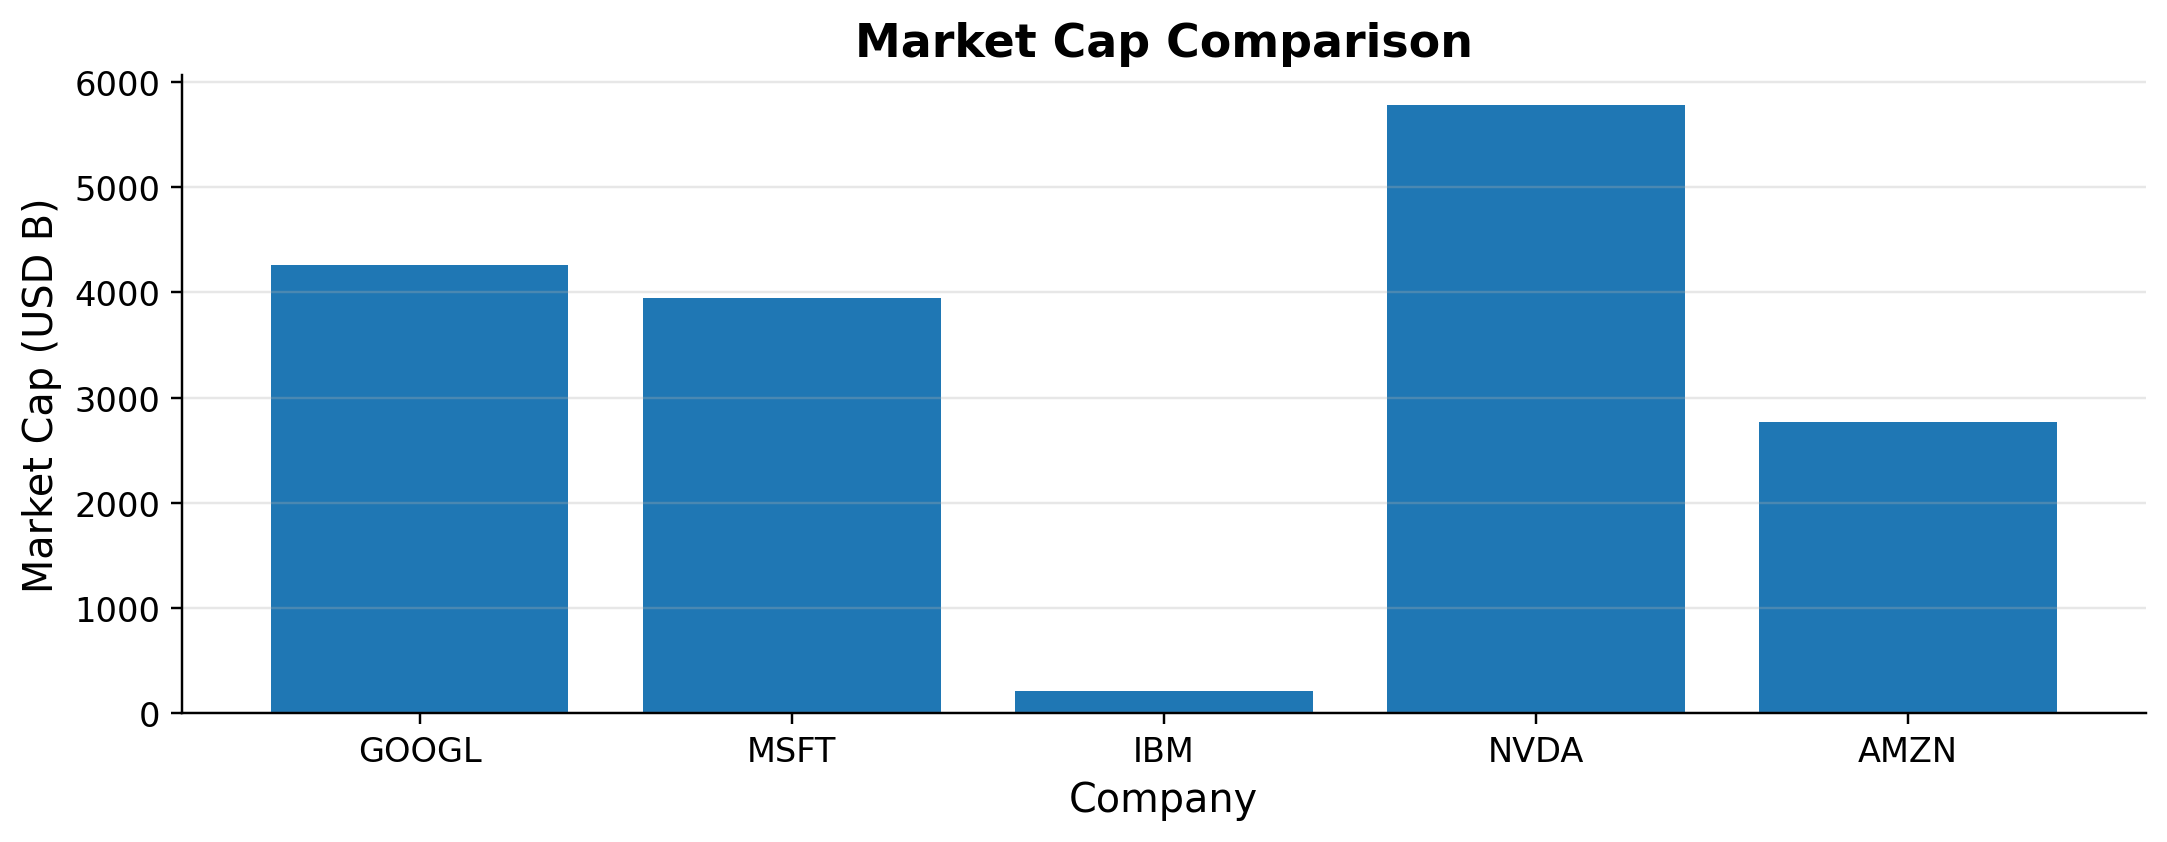

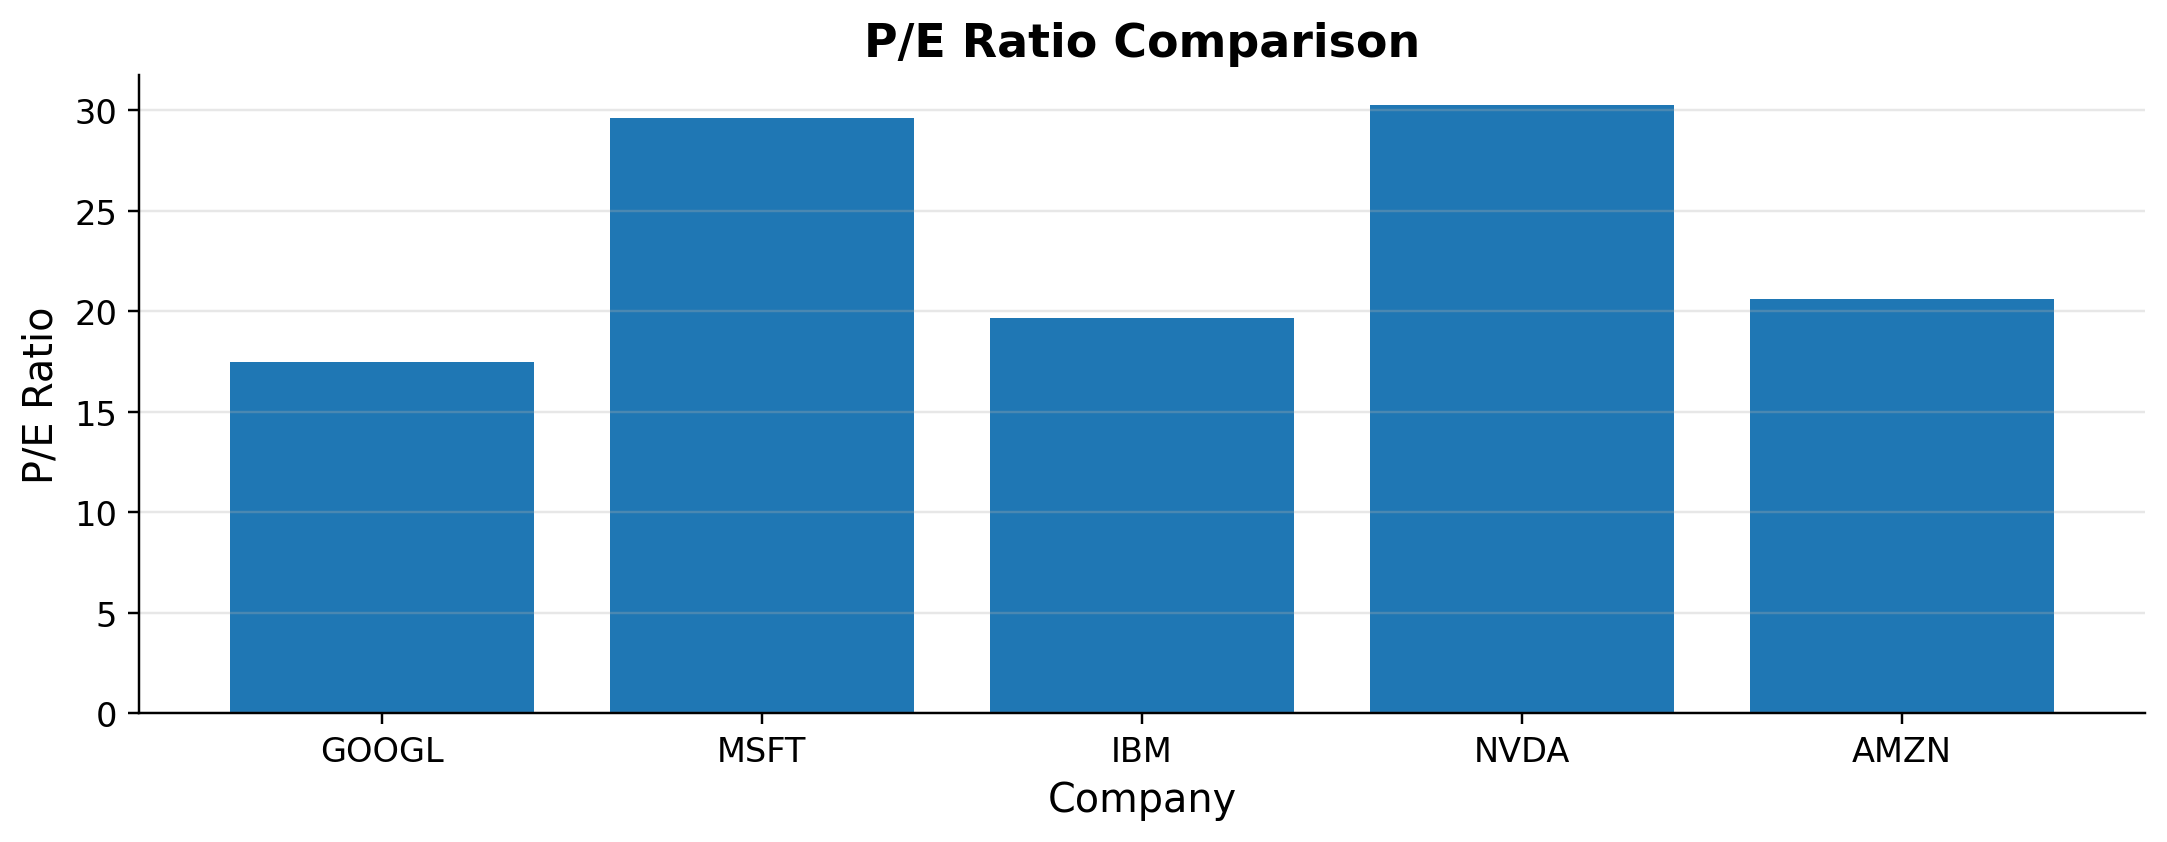

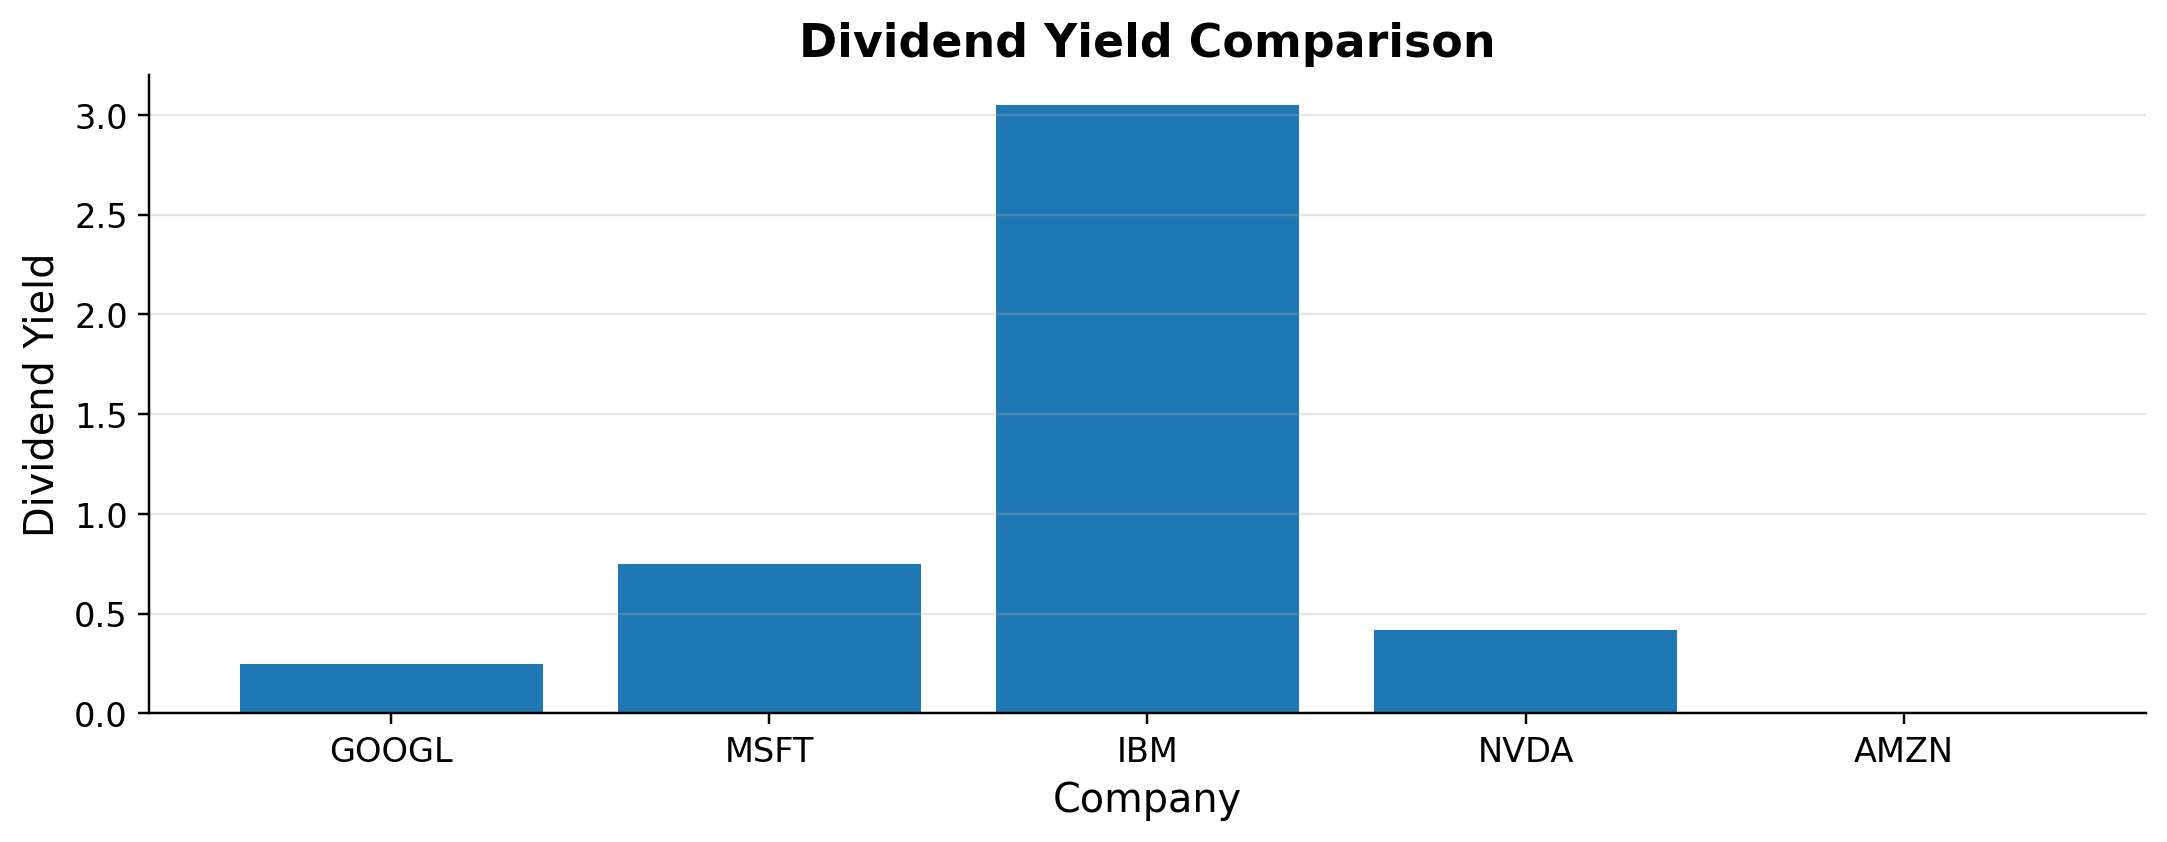

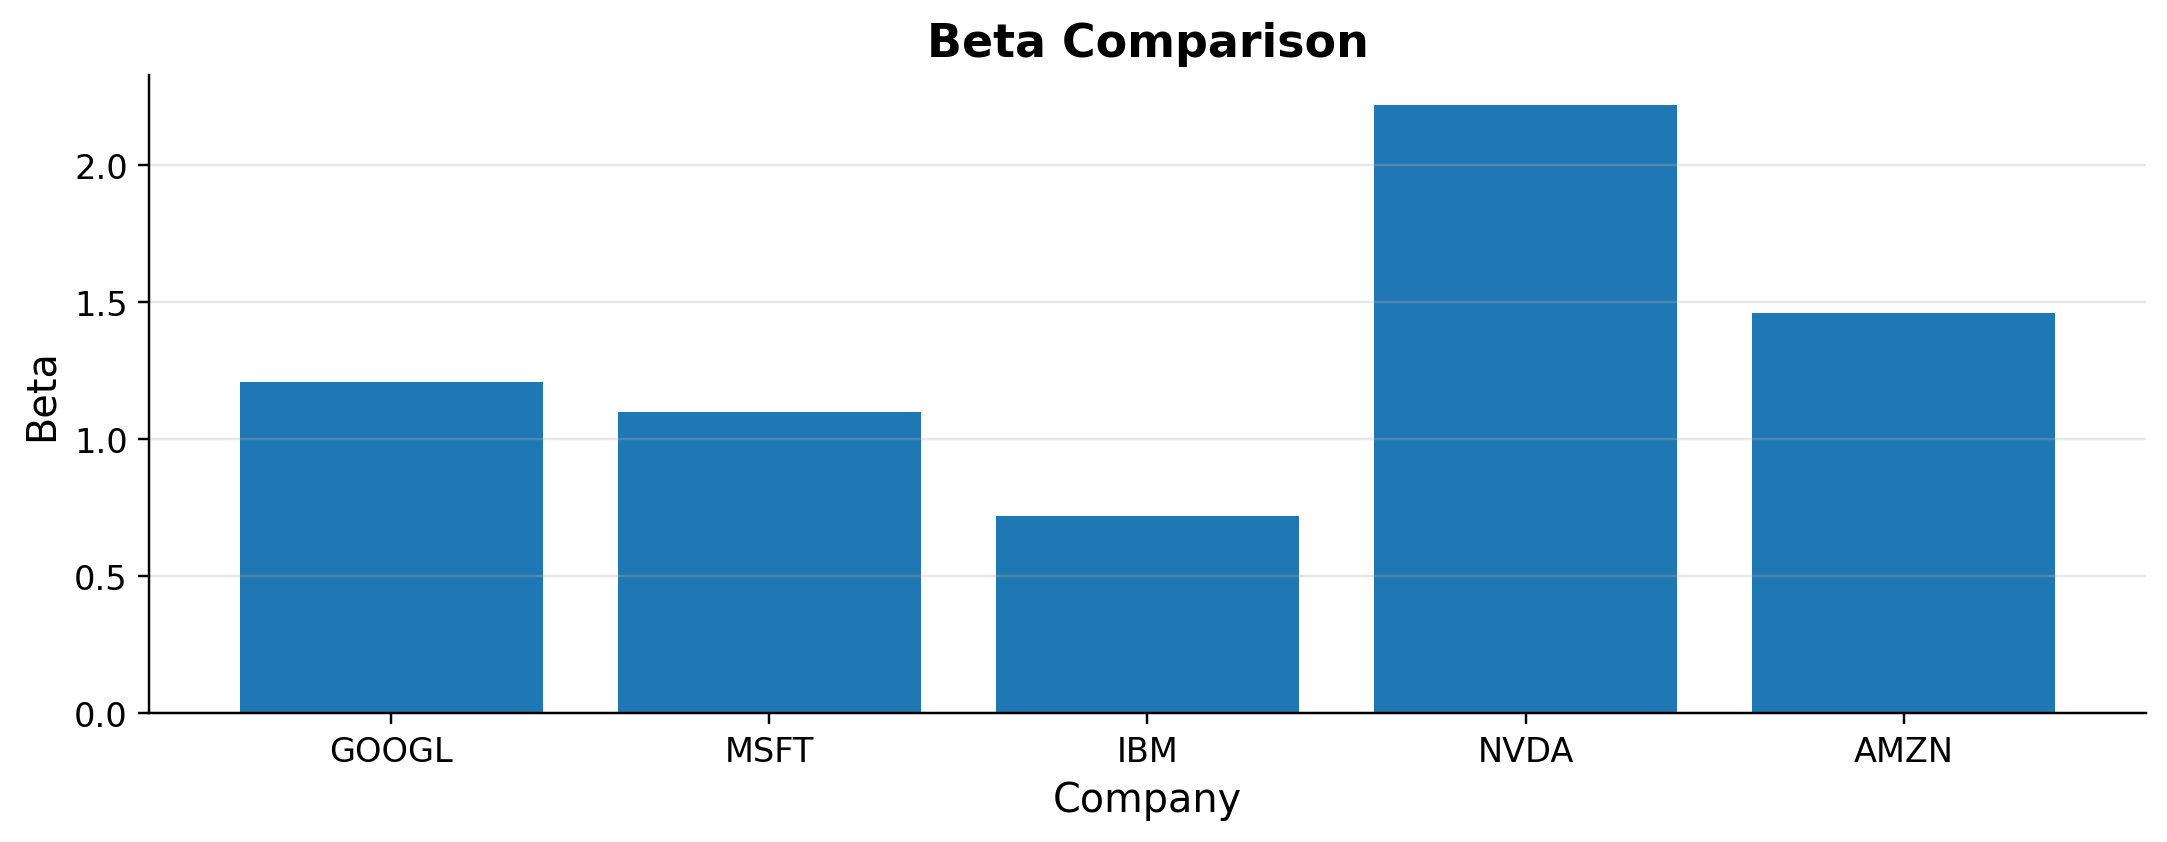

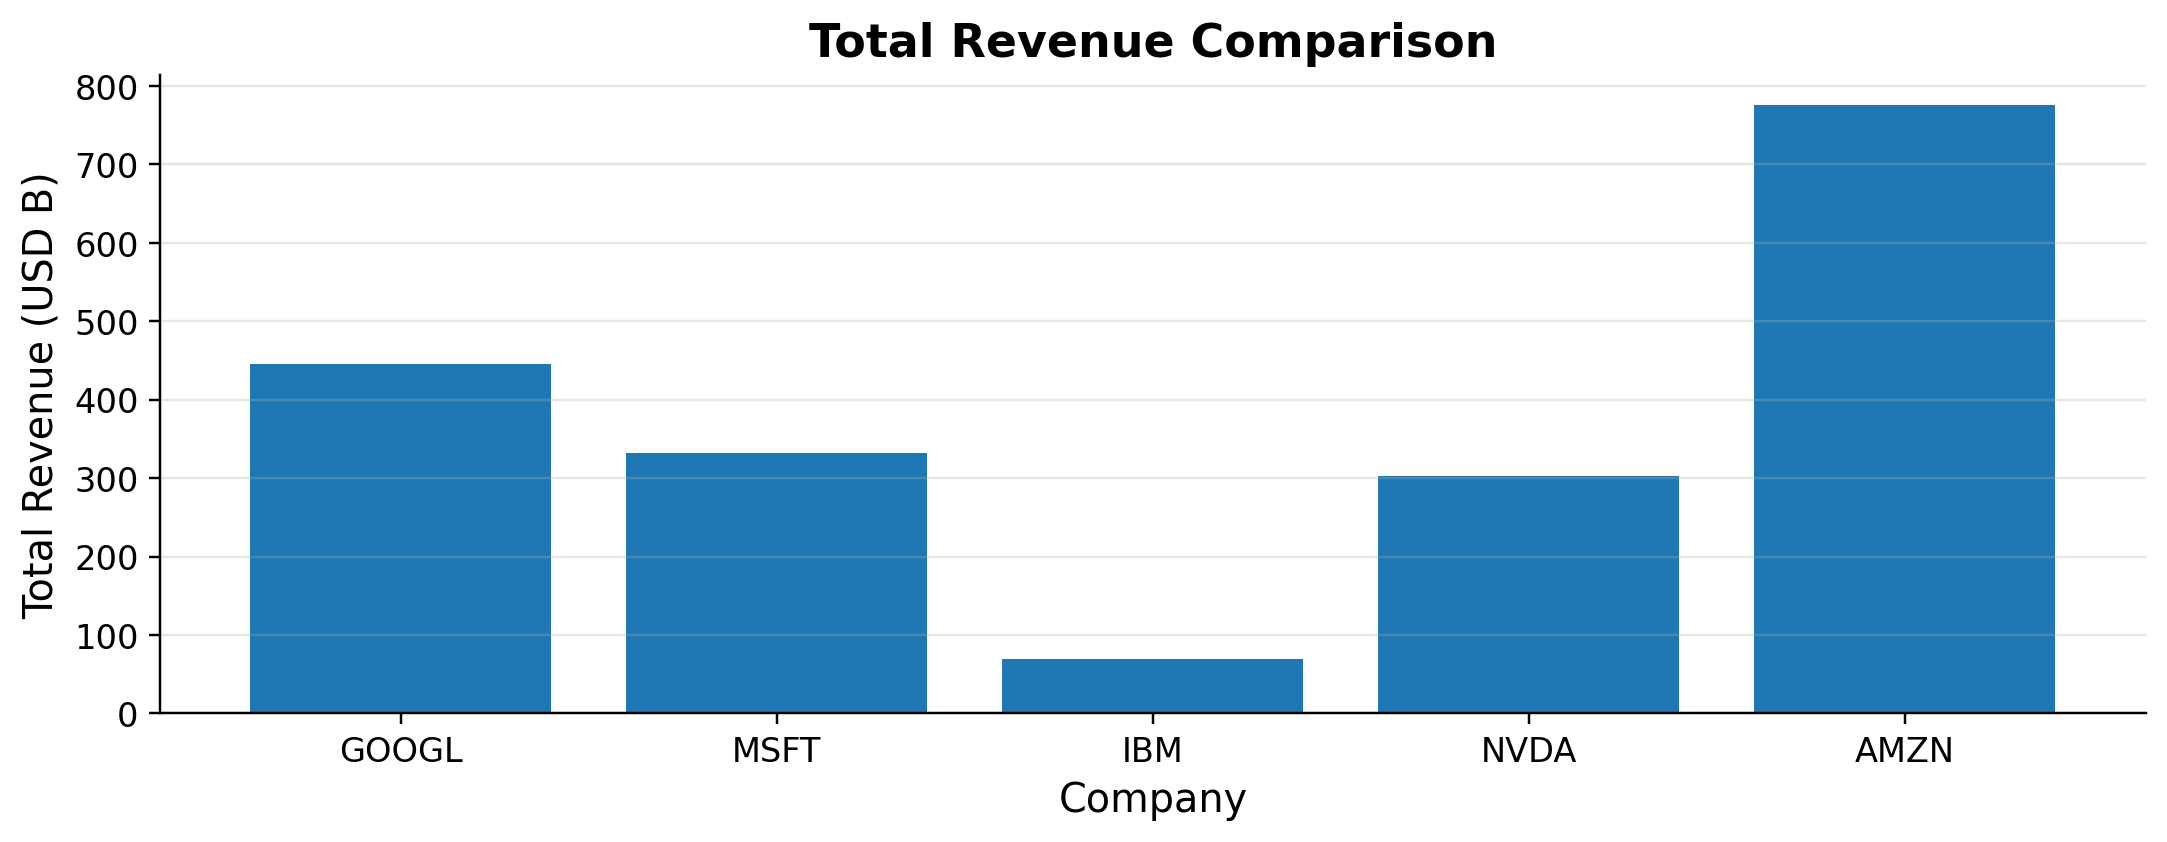

In [62]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Per-metric comparison charts
# ═══════════════════════════════════════════════════════════════════════════
# One bar chart per metric, comparing all five companies.
# ───────────────────────────────────────────────────────────────────────────
metrics_to_plot = ["Market Cap", "P/E Ratio", "Dividend Yield", "Beta", "Total Revenue"]

for metric in metrics_to_plot:
    plt.figure(figsize=(10, 4))
    plt.bar(fin_df.index, fin_df[metric])     # My CODE: bar chart of fin_df[metric] across companies
    plt.title(f"{metric} Comparison")
    plt.ylabel(f"{metric} (USD B)" if metric in ["Market Cap", "Total Revenue"] else metric)
    plt.xlabel("Company")
    plt.grid(axis='y', alpha=0.3)
    plt.grid(axis='x', visible=False)
    plt.tight_layout()
    plt.show()

### 🔎 Your Observations — The Financial Lens

*Write 2–4 bullets. Consider:*
- *Which company do the metrics suggest is "priced for growth", and which looks like a defensive/dividend profile? What evidence?*
- *What investment-relevant question can these numbers NOT answer — and where would that answer live instead?*
- *Note: yfinance returns live data, so describe the pattern you actually see in your run.*

### My Observations
- **NVDA and MSFT are priced for growth, and IBM has the defensive, dividend-paying profile.** NVDA has the highest P/E (30.27) and by far the highest Beta (2.22), with a dividend yield of just 0.42%: investors are paying for expected AI-driven growth and accepting the volatility. MSFT is close behind on valuation (P/E 29.61) but much steadier (Beta 1.10). IBM is the opposite: the highest dividend yield (3.05%), the lowest Beta (0.72) and a modest P/E (19.69), the classic income profile, but it's also far smaller (208.72B market cap against 2,767–5,782B for the others).
- **Size and valuation point in different directions.** AMZN has by far the highest revenue (775.68B, more than double NVDA's 302.97B) yet trades at a P/E of only 20.64 and pays no dividend. GOOGL is the cheapest on earnings (P/E 17.49) despite the second-largest market cap. A ranking based on market cap alone would miss both of these.
- **These numbers can't say *why* a company is valued the way it is or whether its AI bets will pay off.** They don't show which initiatives drive growth, how mature they are, when they ship or what could derail them. They are also a single live snapshot, not a trend. That information lives in the unstructured AI-initiative documents, which is why the system needs the second (RAG) lens.

<a name='section5'></a>
## 5️⃣ **Step 2 — Narrative Lens: Document Ingestion & Vectorization**

The qualitative half. Five PDF reports (one per company) describing each organization's AI initiatives — summaries, objectives, timelines, investments, risks.

**The one design decision that matters most in this section:** every chunk gets a `company` **metadata tag** derived from its source filename. In the failed pilot, a question about MSFT could be answered from GOOGL passages because all documents lived in one undifferentiated pool. The tag is what lets us *filter* retrieval per company in Step 3 — and *measure* how much that filter helps.

In [63]:
# 📂 Unzip the AI-initiative documents into the working directory.
ZIP_PATH    = "/content/Project_Datafiles.zip"
EXTRACT_DIR = "/content/"
PDF_DIR     = "/content/Companies-AI-Initiatives"

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

pdf_files = sorted(f for f in os.listdir(PDF_DIR) if f.endswith(".pdf"))
print("Documents found:", pdf_files)

Documents found: ['AMZN.pdf', 'GOOGL.pdf', 'IBM.pdf', 'MSFT.pdf', 'NVDA.pdf']


In [64]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Load PDFs and tag every page with its company
# ═══════════════════════════════════════════════════════════════════════════
# This tag is what makes company-filtered retrieval possible in Step 3 — the
# fix for the pilot's company-mix-up failures. (It's also why we load each
# file individually instead of using PyPDFDirectoryLoader.)
# ───────────────────────────────────────────────────────────────────────────
documents = []

for fname in pdf_files:
    ticker = fname.replace(".pdf", "")     # "MSFT.pdf" -> "MSFT"
    loader = PyPDFLoader(os.path.join(PDF_DIR,fname))     # My CODE: a PyPDFLoader for this file's full path
    pages  = loader.load()    # My CODE: load the file (one Document per page)
    for page in pages:
        page.metadata["company"] = ticker                # My CODE: set this page's "company" metadata to the ticker
        page.page_content = " ".join(page.page_content.split())   # My CODE: clean up broken whitespace
    documents.extend(pages)

print(f"Loaded {len(documents)} pages across {len(pdf_files)} companies.")

Loaded 44 pages across 5 companies.


In [65]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Token-based chunking
# ═══════════════════════════════════════════════════════════════════════════
# Split the tagged pages into overlapping, token-sized chunks. Token-based
# splitting aligns chunk sizes with what the models actually count, and
# splitting Documents (not raw text) carries your company tag onto every chunk.
# 💡 Hint: the splitter has a class method for tiktoken-based sizing
#          ('cl100k_base'), and a method that splits Document objects while
#          preserving their metadata.
# ───────────────────────────────────────────────────────────────────────────
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name='cl100k_base',
    chunk_size= CHUNK_SIZE, # 512 tokens per chunk # My CODE: using the constant from Section 3.3
    chunk_overlap= CHUNK_OVERLAP, #64 tokens shared between neighbors  # My CODE: using the constant from Section 3.3
)

chunks = text_splitter.split_documents(documents)    # My CODE: split `documents` so metadata is preserved
print(f"Total chunks: {len(chunks)}")

Total chunks: 44


In [66]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Sanity-check the chunks
# ═══════════════════════════════════════════════════════════════════════════
# 💡 Hint: collections.Counter over each chunk's company metadata is a one-liner.
# ───────────────────────────────────────────────────────────────────────────
chunk_counts = Counter(chunk.metadata["company"] for chunk in chunks) # My CODE: chunks per company
print("Chunks per company:", dict(chunk_counts))
print()
print("--- Sample chunk (first 400 chars) ---")
print(chunks[0].page_content[:400])      # My CODE: print the first ~400 chars of one chunk
print(chunks[0].metadata)                # My CODE: print that chunk's metadata (confirm the company tag)

Chunks per company: {'AMZN': 9, 'GOOGL': 7, 'IBM': 8, 'MSFT': 9, 'NVDA': 11}

--- Sample chunk (first 400 chars) ---
Amazon is a global technology and e-commerce giant that uses AI to enhance almost every part of its business. In retail, AI powers product recommendations, dynamic pricing, fraud detection, and supply chain optimization, making shopping faster and more personalized. Amazon Web Services (AWS) offers AI and machine learning tools that help businesses build intelligent applications, from natural lang
{'producer': 'Skia/PDF m142 Google Docs Renderer', 'creator': 'PyPDF', 'creationdate': '', 'title': 'AI Initiatives', 'source': '/content/Companies-AI-Initiatives/AMZN.pdf', 'total_pages': 9, 'page': 0, 'page_label': '1', 'company': 'AMZN'}


In [67]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Embed and store in ChromaDB
# ═══════════════════════════════════════════════════════════════════════════
embedding_model = OpenAIEmbeddings(model=EMBEDDING_MODEL)   # My CODE: the EMBEDDING_MODEL constant

vectorstore = Chroma.from_documents(
    chunks,                                        # My CODE: your chunks
    embedding_model,                                        # My CODE: your embedding model
    collection_name="ai_initiatives",
)

print(f"Vector store ready with {vectorstore._collection.count()} embedded chunks.")

Vector store ready with 88 embedded chunks.


### 🔎 Your Observations — Ingestion & Vectorization

*Write 2–3 bullets. Consider:*
- *Are chunk counts balanced across companies, and why would an imbalance distort retrieval?*
- *The five companies describe their AI work in very similar language ("cloud AI platform", "foundation models"). What does the metadata tag guarantee that embedding similarity alone might not — and in which kinds of queries does that guarantee matter most?*
- *What trade-off do CHUNK_SIZE / CHUNK_OVERLAP control?*

### My Observations
- **Chunk counts are roughly balanced (AMZN 9, GOOGL 7, IBM 8, MSFT 9, NVDA 11), but the ingestion has a bug: the vector store holds 88 embeddings for 44 chunks.** Exactly double means the embedding cell was run twice in the same Colab session, and `Chroma.from_documents` added a second copy to the existing in-memory `ai_initiatives` collection. With `TOP_K = 4`, a search can return the same chunk twice, so the model may see as few as 2 distinct passages. That probably contributes to some of the 5 gold-set retrieval misses, and it also affects the 3-chunk ranking digests. The imbalance matters too: NVDA has 57% more chunks than GOOGL, so an unfiltered search is more likely to surface NVIDIA text just because there is more of it.
- **The `company` metadata tag guarantees the evidence comes from the right company, which embedding similarity can't.** All five companies describe their AI work in near-identical language ("foundation models", "cloud AI platform", "custom accelerators"), so a query like *"Which custom accelerator targets model training?"* is about equally close to Amazon's Trainium, Google's TPU and NVIDIA's GPUs. The filter makes retrieval exact for single-company questions and keeps the ranking digests attributable to each company. It matters most for questions that don't name the company and when the corpus grows to many similar companies.
- **CHUNK_SIZE (512 tokens) and CHUNK_OVERLAP (64) trade context against precision.** Larger chunks give the model more surrounding context but blur each embedding across several topics. Smaller chunks match queries more precisely but can cut a fact away from the context that explains it. Overlap keeps facts at chunk boundaries from being split, at the cost of storing some text twice. Here, 44 pages produced exactly 44 chunks: every page fits under 512 tokens, so the splitter never actually split anything, and chunking was effectively one chunk per page.

<a name='section6'></a>
## 6️⃣ **Step 3 — Grounded Q&A: The RAG Pipeline**

### 6.1 · Prompt design

The grounding contract lives in the system prompt: the model may use **only** the supplied context (marked `###Context`), must answer the question (marked `###Question`), and must reply exactly **"I don't know."** when the context lacks the answer. This is the guardrail the failed pilot never had — it converts "confident fabrication" into an honest, detectable miss.

In [68]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Write the v1.0 grounding system prompt
# ═══════════════════════════════════════════════════════════════════════════
# Write the rules INSIDE the triple quotes. The prompt must instruct the model to:
#   • Use ONLY the information in the supplied context
#   • Respond EXACTLY with: "I don't know." when the context lacks the answer
#   • Never reference the context's structure (no "based on the context...")
#
# ⚠️ Keep it MINIMAL — resist adding extra instructions. This is deliberately
#    your v1.0: Step 4 will measure its weaknesses and Step 5 will let GEPA
#    evolve it. Hand-tuning it now destroys the experiment.
# ───────────────────────────────────────────────────────────────────────────
qna_system_message = """
Use ONLY the information in the supplied context. 
Respond EXACTLY with: "I don't know." when the context lacks the answer. 
Never reference the context's structure (no "based on the context...").
"""

In [69]:
# User message template — slots the retrieved context and the user question into a single turn
qna_user_message_template = """
###Context
{context}

###Question
{question}
"""

### 6.2 · Company-filtered retrieval

`retrieve()` is the single retrieval doorway for the whole notebook. Pass a `company` ticker and Chroma restricts the similarity search to that company's chunks; pass `None` (for cross-company questions) and it searches the full pool.

In [70]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Build the retrieval helper
# ═══════════════════════════════════════════════════════════════════════════
# Every retrieval in this notebook goes through retrieve().
# 💡 Hint: vectorstore.similarity_search() accepts a `filter` argument that
#          takes a metadata dictionary.
# ───────────────────────────────────────────────────────────────────────────
def retrieve(question: str, company: str | None = None, k: int = TOP_K):
    """Return the top-k most similar chunks, optionally restricted to one company.

    Args:
        question: Natural-language question to embed and search with.
        company:  Ticker like "MSFT" to filter on, or None for the full pool.
        k:        Number of chunks to return.
    """
    search_filter = {"company": company} if company else None  # My CODE: a metadata filter dict when company is given, else None
    return vectorstore.similarity_search(question, k=k, filter=search_filter)             # YOUR CODE: similarity search with k and the filter


def format_context(docs) -> str:
    """Join retrieved chunks into a single context string."""
    return "\n\n".join(doc.page_content for doc in docs)    # provided

In [71]:
# 🧪 Demonstrate retrieval end-to-end before wiring the LLM in:
# ask an MSFT question, confirm every returned chunk is tagged MSFT.
demo_question = "What is Microsoft's flagship AI assistant product?"
demo_chunks = retrieve(demo_question, company="MSFT")

print(f"Retrieved {len(demo_chunks)} chunks. Company tags:",
      [c.metadata["company"] for c in demo_chunks])
print()
print("--- First chunk (first 400 chars) ---")
print(demo_chunks[0].page_content[:400])

Retrieved 4 chunks. Company tags: ['MSFT', 'MSFT', 'MSFT', 'MSFT']

--- First chunk (first 400 chars) ---
● Enterprise Enablement : Provides organizations with tools to integrate AI into their operations, improving efficiency, decision-making, and innovation. ● Ecosystem Growth : Strengthens the Microsoft ecosystem by integrating Foundry Labs with Azure, Microsoft 365, and GitHub, fostering an end-to-end AI development environment. Risks / Challenges Despite its potential, Azure AI Foundry Labs faces 


### 6.3 · The RAG function

In [72]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — The grounded RAG function: retrieve -> assemble -> answer
# ═══════════════════════════════════════════════════════════════════════════
qna_prompt = ChatPromptTemplate.from_messages([
    ("system", qna_system_message),
    ("user", qna_user_message_template),
])                                              # provided

def rag_answer(question: str, company: str | None = None) -> str:
    """Answer a question using retrieval-augmented generation.

    Args:
        question: The user's natural-language question.
        company:  Optional ticker to restrict retrieval to one company's documents.
    Returns:
        The model's answer, grounded in the retrieved context.
    """
    relevant_chunks = retrieve(question, company=company)    # My CODE: retrieve, passing the company filter through
    context = format_context(relevant_chunks)            # My CODE: format the chunks into one context string

    messages = qna_prompt.format_messages(context=context, question=question)  # My CODE: format qna_prompt with the context and question
    response = llm.invoke(messages)  # My CODE: invoke `llm` with the messages
    return response.content

### 6.4 · Typed test suite

Five queries, each probing a different capability. (These are smoke tests for *behaviour*; the rigorous *measurement* happens in Step 4.)

### Example 1: Factual lookup — a single specific fact from one company's document.

In [73]:
# Example 1: factual lookup (single fact, single company)
print(rag_answer("What is Microsoft's flagship AI assistant product brand?", company="MSFT"))

I don't know.


### Example 2: Listing question — can retrieval surface multiple related facts in one answer?

In [74]:
# Example 2: listing / multi-fact recall
print(rag_answer("What are the main AI initiatives NVIDIA is working on?", company="NVDA"))

I don't know.


### Example 3: Cross-company comparison — retrieval over the **full pool** (company=None), since the question spans two companies.

In [75]:
# Example 3: cross-company comparison — no filter, the question itself names both companies
print(rag_answer("How does Google's AI focus differ from Microsoft's AI focus?", company=None))

I don't know.


### Example 4: Multi-hop synthesis — connecting facts across chunks of the same document.

In [76]:
# Example 4: multi-hop synthesis — links Amazon's customer-facing platform to its in-house foundation model
print(rag_answer("What is Amazon's foundation-model platform, and what foundation model has Amazon developed in-house?", company="AMZN"))

I don't know.


### Example 5: Out-of-scope trap — validates the **"I don't know"** guardrail. The documents describe AI initiatives, not quarterly financials, so the only correct answer is an honest miss.

In [77]:
# Example 5: out-of-scope — tests the "I don't know" guardrail
print(rag_answer("What was IBM's exact revenue in the third quarter of 2025?", company="IBM"))

I don't know.


In [78]:
# ═══════════════════════════════════════════════════════════════════════════
# 🔍 DIAGNOSTIC — Is the "I don't know." a retrieval failure or a generation failure?
# ═══════════════════════════════════════════════════════════════════════════
# Example 1 returned "I don't know." even though MSFT.pdf describes Microsoft
# 365 Copilot. This cell skips the LLM and checks retrieval on its own:
# does the expected answer ("Copilot") appear in the chunks retrieve() returns?
#   • False → retrieval failure: the answer never reached the model.
#   • True  → retrieval works, so the refusal comes from the generation step
#             (the v1.0 prompt).
# Result: True. Copilot is in the 2nd of the 4 retrieved MSFT chunks, so the
# refusal comes from the v1.0 prompt, not the retriever.
# ───────────────────────────────────────────────────────────────────────────
q = "What is Microsoft's flagship AI assistant product brand?"
ctx = format_context(retrieve(q, company="MSFT"))
print("Copilot in context?", "copilot" in ctx.lower())
print(ctx[:2000])


Copilot in context? True
● Enterprise Enablement : Provides organizations with tools to integrate AI into their operations, improving efficiency, decision-making, and innovation. ● Ecosystem Growth : Strengthens the Microsoft ecosystem by integrating Foundry Labs with Azure, Microsoft 365, and GitHub, fostering an end-to-end AI development environment. Risks / Challenges Despite its potential, Azure AI Foundry Labs faces several risks: ● Security and Privacy : Handling sensitive enterprise data requires robust safeguards and continuous monitoring. ● Model Reliability and Bias : Experimental models must be validated to ensure fairness, accuracy, and consistency before enterprise deployment. ● Scalability and Performance : Ensuring the platform can accommodate growing numbers of users and experimental workloads without compromising performance. ● Regulatory Compliance : Navigating global AI regulations and ensuring compliance with privacy and safety standards remains a complex challenge.

In [79]:
# ═══════════════════════════════════════════════════════════════════════════
# 🔍 DIAGNOSTIC 2 — Same context, two wordings: is the v1.0 prompt too strict?
# ═══════════════════════════════════════════════════════════════════════════
# Diagnostic 1 showed retrieval works. This cell checks the generation step:
#   1. Print the system prompt actually in use (rules out a stale prompt).
#   2. Confirm "Copilot" is in the user message the LLM receives.
#   3. Ask the original question, then a reworded one, with the SAME context.
# Result: the prompt is current and Copilot is in the message, but the
# "flagship ... brand" question gets "I don't know." while "What is Microsoft
# 365 Copilot?" gets a full, accurate answer. Only the wording changed, so the
# strict v1.0 rules make the model refuse whenever the question uses words the
# context doesn't contain ("flagship", "brand"). I left the prompt unchanged
# so Step 4 can measure this and Step 5 (GEPA) can address it.
# ───────────────────────────────────────────────────────────────────────────
q = "What is Microsoft's flagship AI assistant product brand?"
ctx = format_context(retrieve(q, company="MSFT"))
msgs = qna_prompt.format_messages(context=ctx, question=q)

print(repr(msgs[0].content))      # the system prompt actually in use
print("Copilot in user msg?", "copilot" in msgs[1].content.lower())
print(llm.invoke(msgs).content)   # original wording → "I don't know."

# Same context, softer question wording
q2 = "What is Microsoft 365 Copilot?"
print(llm.invoke(qna_prompt.format_messages(context=ctx, question=q2)).content)  # → full answer


'\nUse ONLY the information in the supplied context. \nRespond EXACTLY with: "I don\'t know." when the context lacks the answer. \nNever reference the context\'s structure (no "based on the context...").\n'
Copilot in user msg? True
I don't know.
Microsoft 365 Copilot is an AI-powered productivity assistant embedded across Microsoft 365 applications, including Word, Excel, PowerPoint, Outlook, and Teams. It leverages large language models (LLMs) and Microsoft Graph to provide contextual, intelligent assistance—drafting content, analyzing data, summarizing meetings, and automating repetitive tasks. The initiative aims to enhance productivity by integrating generative AI capabilities directly into everyday business workflows, enabling users to work faster and make data-driven decisions.


### 🔍 Observation: v1.0 Prompt Over-Refuses Despite Correct Retrieval

**Symptom.** With the v1.0 grounding prompt, `rag_answer()` returned *"I don't know."* for in-scope questions whose answers are in the source PDFs. Example: *"What is Microsoft's flagship AI assistant product brand?"* (expected: Microsoft 365 Copilot).

**Diagnosis.** I tested each stage of the pipeline separately:

| Check | Result | Conclusion |
|---|---|---|
| Is "Copilot" in the retrieved MSFT chunks? | ✅ Yes (2nd of 4 chunks) | Retrieval works |
| Is it in the user message sent to the LLM? | ✅ Yes | Prompt assembly works |
| Is the active system prompt the current v1.0? | ✅ Yes | No stale state |
| Same context, question *"…flagship AI assistant product brand?"* | ❌ "I don't know." | Generation fails |
| Same context, question *"What is Microsoft 365 Copilot?"* | ✅ Full, accurate answer | The model *can* answer |

**Root cause.** The failure is in **generation, not retrieval**. The strict v1.0 rules ("Use ONLY the information…", "Respond EXACTLY with 'I don't know.'…") lead gpt-4o-mini (temperature 0) to treat any question wording the context doesn't contain word for word (here "flagship" and "brand") as missing information, so it refuses. Identical context gives opposite outcomes depending only on how the question is phrased.

**Why I left it unchanged.** The v1.0 prompt is meant to be a minimal baseline. Hand-tuning it now would weaken the Step 4 → Step 5 comparison. I expect:
- **Step 4** to show high *context relevance* but low *answer relevance / correctness*, pointing at the generator rather than the retriever.
- **Step 5 (GEPA)** to evolve a prompt that answers reasonably reworded in-scope questions while still refusing truly out-of-scope ones (e.g., IBM's Q3 2025 revenue, which the documents don't contain).

> **Caveat:** An over-strict baseline can exaggerate how much GEPA improves things. I'll note this when interpreting the before/after scores.


### 6.5 · Retrieval diagnostics with the gold dataset

`golden_retrieval.csv` contains **20 questions** (4 per company), each with:

| Column | Meaning |
|---|---|
| `question` | A question answerable from exactly one company's document |
| `ticker_hint` | Which company's document holds the answer |
| `expected_substring` | A short, verified token (e.g., *Copilot*, *Granite*, *Bedrock*) that a correct answer **must** contain |

Here we use it to answer a question the judges in Step 4 *cannot* answer on their own: **when the system fails, is it the retriever's fault or the generator's fault?** We check whether the expected token appears in the *retrieved chunks* (before any LLM is involved) — with the company filter on vs. off.

In [80]:
# 📂 Load the gold dataset
gold = pd.read_csv("/content/golden_retrieval.csv")
print(f"{len(gold)} gold questions, balanced across companies:")
print(gold["ticker_hint"].value_counts().to_dict())
gold.head()

20 gold questions, balanced across companies:
{'MSFT': 4, 'GOOGL': 4, 'IBM': 4, 'NVDA': 4, 'AMZN': 4}


,question,ticker_hint,expected_substring
0,What is Microsoft's flagship AI assistant product brand?,MSFT,Copilot
1,Which Microsoft cloud platform hosts AI services?,MSFT,Azure
2,What is Microsoft's AI development platform for foundation models?,MSFT,Foundry
3,Which Microsoft tool delivers AI-assisted code completion?,MSFT,IntelliCode
4,What is Google's primary foundation-model family?,GOOGL,Gemini


In [81]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Retrieval-only diagnostic: filter ON vs filter OFF
# ═══════════════════════════════════════════════════════════════════════════
# An LLM-FREE measurement of the retriever using the gold dataset: you write
# the per-question diagnostic; the loop and summary are provided.
# 💡 Hint: lowercase both sides before the substring check.
# ───────────────────────────────────────────────────────────────────────────
def retrieval_diagnostic(row, use_filter: bool) -> dict:
    """For one gold row: did the expected token reach the retrieved chunks,
    and (for unfiltered retrieval) what share of chunks belong to the right company?"""
    company = row["ticker_hint"] if use_filter else None  # My CODE: the row's ticker_hint when use_filter, else None
    docs    = retrieve(row["question"],company=company)  # My CODE: retrieve this row's question with that company setting
    text    = format_context(docs).lower()  # My CODE: join the retrieved chunks' text, lowercased
    return {
        "hit": row["expected_substring"].lower() in text,   # My CODE: is the row's expected_substring (lowercased) in the text?
        "purity": sum(d.metadata["company"]==row["ticker_hint"] for d in docs)/len(docs),   # My CODE: fraction of docs whose company metadata == the row's ticker_hint
    }

# ── Provided: run the diagnostic over the whole gold set ──────────────────────
diag_rows = []
for _, row in gold.iterrows():
    with_f    = retrieval_diagnostic(row, use_filter=True)
    without_f = retrieval_diagnostic(row, use_filter=False)
    diag_rows.append({
        "ticker":                row["ticker_hint"],
        "expected":              row["expected_substring"],
        "hit_with_filter":       with_f["hit"],
        "hit_without_filter":    without_f["hit"],
        "purity_without_filter": round(without_f["purity"], 2),
    })

diag_df = pd.DataFrame(diag_rows)
print(f"Retrieval hit-rate WITH company filter   : {diag_df['hit_with_filter'].mean():.0%}")
print(f"Retrieval hit-rate WITHOUT company filter: {diag_df['hit_without_filter'].mean():.0%}")
print(f"Avg. right-company purity without filter : {diag_df['purity_without_filter'].mean():.0%}")
diag_df

Retrieval hit-rate WITH company filter   : 75%
Retrieval hit-rate WITHOUT company filter: 75%
Avg. right-company purity without filter : 100%


,ticker,expected,hit_with_filter,hit_without_filter,purity_without_filter
0,MSFT,Copilot,True,True,1.0
1,MSFT,Azure,True,True,1.0
2,MSFT,Foundry,True,True,1.0
3,MSFT,IntelliCode,True,True,1.0
4,GOOGL,Gemini,True,True,1.0
5,GOOGL,TPU,False,False,1.0
6,GOOGL,DeepMind,True,True,1.0
7,GOOGL,Astra,True,True,1.0
8,IBM,watsonx,True,True,1.0
9,IBM,Granite,True,True,1.0


In [82]:
# ── Interpretation: filter ON vs OFF + the questions retrieval missed ─────────
diag_df["question"] = gold["question"].values  # diag_rows were built in gold order

hit_on   = diag_df["hit_with_filter"].mean()
hit_off  = diag_df["hit_without_filter"].mean()
purity   = diag_df["purity_without_filter"].mean()
misses   = diag_df[~diag_df["hit_with_filter"]]

print("RETRIEVAL DIAGNOSTIC — INTERPRETATION")
print("=" * 75)
print(f"""
1. Company filter: Hit rate is {hit_on:.0%} with the filter and {hit_off:.0%} without it.
   Purity without the filter is {purity:.0%}, so even unfiltered search returns
   almost only chunks from the right company. The gold questions name the
   company or its products, which already steers the search to the right
   document. On this gold set the filter adds little, but it costs nothing
   and still matters for vaguer questions that don't name a company.

2. Misses: {len(misses)} of {len(diag_df)} questions fail even WITH the filter.
   The right document was searched, but the chunk holding the answer didn't
   rank in the top {TOP_K}. Likely causes: k is too small, chunk boundaries split
   the answer from its context, or the question's wording differs from the
   source text. These failures come from chunking and ranking, not from
   mixing up companies.

3. Implication: {hit_on:.0%} is the most end-to-end accuracy can reach, because
   the LLM can't produce a token that was never retrieved. Better chunking or
   a larger k would help more than further filtering.
""")

print(f"Questions where retrieval missed the expected token ({len(misses)}):")
print("-" * 75)
for _, r in misses.iterrows():
    print(f"[{r['ticker']}] {r['question']}")
    print(f"      expected token: '{r['expected']}'   "
          f"(hit without filter: {r['hit_without_filter']})\n")


RETRIEVAL DIAGNOSTIC — INTERPRETATION

1. Company filter: Hit rate is 75% with the filter and 75% without it.
   Purity without the filter is 100%, so even unfiltered search returns
   almost only chunks from the right company. The gold questions name the
   company or its products, which already steers the search to the right
   document. On this gold set the filter adds little, but it costs nothing
   and still matters for vaguer questions that don't name a company.

2. Misses: 5 of 20 questions fail even WITH the filter.
   The right document was searched, but the chunk holding the answer didn't
   rank in the top 4. Likely causes: k is too small, chunk boundaries split
   the answer from its context, or the question's wording differs from the
   source text. These failures come from chunking and ranking, not from
   mixing up companies.

3. Implication: 75% is the most end-to-end accuracy can reach, because
   the LLM can't produce a token that was never retrieved. Better chunking 

### 🔎 Your Observations — RAG Pipeline & Retrieval Diagnostics

*Write 3–4 bullets. Consider:*
- *Did the guardrail behave on your Example 5? Why is an honest miss safer than a confident fabrication?*
- *Compare the with-filter and without-filter hit-rates and the purity number. Did the filter change the result on THIS gold set — and if not, why not? (Look at how the gold questions are phrased.) When would the filter still earn its keep?*
- *Any gold questions where the expected token never reached the retrieved chunks at all? What does that imply about what prompt optimization can and cannot fix later?*

### My Observations
- **The guardrail behaved correctly on Example 5, but that result alone proves little, because all five typed examples returned *"I don't know."*** The out-of-scope question (IBM's Q3 2025 revenue) should be refused, and it was. But Examples 1–4 were refused too, even though Diagnostic 1 showed "Copilot" was in the retrieved context and Diagnostic 2 showed a less strict wording answered correctly from the same context. So v1.0 refuses almost everything rather than refusing selectively. Even so, an honest miss is the safer failure in investment research. *"I don't know."* is visible and can be sent to a human, while an invented revenue figure looks exactly like a real one and could end up in a client recommendation.
- **The company filter made no difference on this gold set:** 75% hit rate with the filter, 75% without, and 100% right-company chunks either way. That's because every gold question names its company (*"Microsoft's…"*, *"Which AWS service…"*, *"Which NVIDIA…"*), so the company name in the question already steers the embedding search to the right document. The filter becomes essential for questions phrased without a company name (*"Which chip trains large models?"*), for a much larger corpus of similar companies, and for the per-company digests that feed the ranking, where attribution is required.
- **5 of the 20 gold questions (TPU, Quantum, NIM, Flamingo, Trainium) never got the expected token into the retrieved chunks, with or without the filter.** No prompt can fix these, because the generator never sees the answer, so prompt optimization is capped at 15/20 (75%). Those five need retrieval changes: a larger `TOP_K`, removing the duplicate embeddings, hybrid keyword search, or query rewriting. The same limit caps GEPA at 5/8 on the held-out set.

<a name='section7'></a>
## 7️⃣ **Step 4 — Quality Control: LLM-as-Judge Evaluation**

A single good answer is not evidence of a good system. We now measure quality two complementary ways:

- **4A — Subjective (LLM-as-Judge):** three rubric-driven 1–5 scores per answer — **Groundedness**, **Context Relevance**, **Answer Relevance** — over a typed evaluation set that includes one designed-to-fail probe.
- **4B — Objective (gold dataset):** run all 20 gold questions through the pipeline and check the `expected_substring` — a binary, judge-free accuracy number.

Why both? Judges can assess *qualities* (is this grounded? is this relevant?) that no substring can capture — but a `gpt-4o-mini` judge is itself fallible. The objective check cross-validates the judges, and the judges explain *what kind* of failure the objective check found.

### **Evaluation Question Set (4A)**

| # | Type | Why it's in the set |
|---|------|---------------------|
| **Q1** | Easy factual | Baseline — should score high on all three metrics |
| **Q2** | Listing / multi-fact | Tests whether retrieval surfaces enough context for a multi-fact answer |
| **Q3** | Cross-company synthesis | Tests reasoning over an unfiltered, multi-company retrieval |
| **Q4** | **Out-of-scope (expected to fail)** | Asks for financial data the documents don't contain. Should trigger the guardrail and score low on context- and answer-relevance. |
| **Q5** | Specific detail | Tests precision — concrete names/timelines rather than paraphrase |

If every question scored 5/5, the rubric would not be measuring anything — a documented failure case (Q4) is what proves the evaluation is discriminative.

In [83]:
# Five evaluation questions with their retrieval scope. Q4 is intentionally
# unanswerable from the source so we can observe the rubric correctly
# penalising context-relevance and answer-relevance.
evaluation_set = [
    {"question": "What is Google's primary foundation-model family?",                          "company": "GOOGL"},
    {"question": "What are the main AI initiatives IBM is pursuing?",                          "company": "IBM"},
    {"question": "How does NVIDIA's AI strategy differ from Amazon's AI strategy?",            "company": None},
    {"question": "What was Microsoft's total AI revenue for fiscal year 2025?",                "company": "MSFT"},   # out-of-scope trap
    {"question": "What timelines are mentioned for Amazon's foundation-model initiatives?",    "company": "AMZN"},
]

### **Judge Rubric 1 — Groundedness** · *Are the answer's claims actually supported by the retrieved context?*

In [84]:
# User-side template for the groundedness judge — supplies question, context and answer
groundedness_evaluation_message_template = """
###Question
{question}

###Context
{context}

###Answer
{answer}
"""

# System prompt for the groundedness judge — scores how well the answer is
# derived from the provided context, on a 1-5 scale.
# The final "Score: N" line makes the rating machine-readable for the batch evaluator.
groundedness_rater_system_message = """You are tasked with rating AI-generated answers to questions posed by users.
You will be presented a question, the context used by the AI system, and the AI-generated answer.
In the input, the question begins with ###Question, the context begins with ###Context, and the answer begins with ###Answer.

Metric:
Groundedness — the answer should be derived ONLY from the information presented in the context. Claims that do not appear in the context lower the score.

Evaluation criteria (1-5):
1 - The metric is not followed at all
2 - The metric is followed only to a limited extent
3 - The metric is followed to a good extent
4 - The metric is followed mostly
5 - The metric is followed completely

Instructions:
1. Briefly explain, step by step, whether each claim in the answer is supported by the context.
2. Then assign a rating using the evaluation criteria.
3. End your response with a line in EXACTLY this format: Score: <N>
"""

### **Judge Rubric 2 — Context Relevance** · *Did the **retriever** fetch passages capable of answering the question?* (This grades retrieval, not the answer — note its template has no `{answer}` slot.)

In [85]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Write the Context Relevance judge (model it on Rubric 1)
# ═══════════════════════════════════════════════════════════════════════════
# This rubric grades the RETRIEVER, not the answer — so this judge must never
# see the answer. The template and the criteria scale are provided; you write
# the metric definition and instructions, mirroring Rubric 1's structure.
# ───────────────────────────────────────────────────────────────────────────
# Provided: user-side template — question and retrieved context ONLY (no answer)
context_relevance_evaluation_message_template = """
###Question
{question}

###Context
{context}
"""

context_relevance_rater_system_message = """You are tasked with rating the quality of retrieved context for a question-answering system.
You will be presented a question and the context retrieved by the system.
In the input, the question begins with ###Question and the context begins with ###Context.

Metric:
Context Relevance — the retrieved context should contain the information needed to fully answer the question. Missing key facts, passages about the wrong company, topic, or time period, and irrelevant or off-topic content lower the score.


Evaluation criteria (1-5):
1 - The metric is not followed at all
2 - The metric is followed only to a limited extent
3 - The metric is followed to a good extent
4 - The metric is followed mostly
5 - The metric is followed completely

Instructions:
1. Briefly explain, step by step, which parts of the question the context addresses and which information, if any, is missing or irrelevant.
2. Then assign a rating using the evaluation criteria.
3. End your response with a line in EXACTLY this format: Score: <N>
"""

### **Judge Rubric 3 — Answer Relevance** · *Does the answer actually address what was asked?* (No `{context}` slot — this isolates question↔answer fit.)

In [86]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Write the Answer Relevance judge
# ═══════════════════════════════════════════════════════════════════════════
# This rubric grades question<->answer fit in isolation — no context slot. Why?
# ───────────────────────────────────────────────────────────────────────────
# Provided: user-side template — question and answer ONLY
answer_relevance_evaluation_message_template = """
###Question
{question}

###Answer
{answer}
"""

answer_relevance_rater_system_message = """You are tasked with rating AI-generated answers to questions posed by users.
You will be presented a question and the AI-generated answer.
In the input, the question begins with ###Question and the answer begins with ###Answer.

Metric:
Answer Relevance — the answer should directly address the main aspects of the question. Answers that ignore parts of the question, drift off-topic, add unnecessary or unrelated information, or are too vague to be useful lower the score.


Evaluation criteria (1-5):
1 - The metric is not followed at all
2 - The metric is followed only to a limited extent
3 - The metric is followed to a good extent
4 - The metric is followed mostly
5 - The metric is followed completely

Instructions:
1. Briefly explain, step by step, which aspects of the question the answer addresses and which, if any, it misses or goes off-topic on.
2. Then assign a rating using the evaluation criteria.
3. End your response with a line in EXACTLY this format: Score: <N>
"""

### **Running the Evaluation (4A)**

Each question runs through retrieval → generation → all three judges. Every rubric ends with a `Score: <N>` line so the score can be parsed reliably.

In [87]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Score parser
# ═══════════════════════════════════════════════════════════════════════════
# 💡 Hint: re.findall with case-insensitive + multiline matching (the inline
#          flags `(?im)` work) — anchor the "Score:" pattern at line start.
# ───────────────────────────────────────────────────────────────────────────
def extract_score(judge_text: str) -> int:
    """Pull the final 1-5 integer score from a judge response.
    Falls back to the last 1-5 mentioned anywhere if the 'Score: N' line is
    missing (defensive); returns 0 if no digit is found."""
    m = re.findall(r"(?im)^\s*score:\s*([1-5])\b", judge_text)  # My CODE: find all "Score: <N>" line matches (N in 1-5)
    if m:
        return int(m[-1])
    nums = re.findall(r"\b([1-5])\b", judge_text)   # My CODE: fallback — all standalone digits 1-5 anywhere in the text
    return int(nums[-1]) if nums else 0

In [88]:
# Compile each rubric as a reusable ChatPromptTemplate so we can format
# per-question inputs in the evaluation loop below.
groundedness_prompt = ChatPromptTemplate.from_messages([
    ("system", groundedness_rater_system_message),
    ("user", groundedness_evaluation_message_template),
])

context_relevance_prompt = ChatPromptTemplate.from_messages([
    ("system", context_relevance_rater_system_message),
    ("user", context_relevance_evaluation_message_template),
])

answer_relevance_prompt = ChatPromptTemplate.from_messages([
    ("system", answer_relevance_rater_system_message),
    ("user", answer_relevance_evaluation_message_template),
])

In [89]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — The evaluation loop
# ═══════════════════════════════════════════════════════════════════════════
# Run one question through retrieval, generation, and all three judges.
# Note: the groundedness and context-relevance judges must see the SAME
# context the answer was generated from.
# ───────────────────────────────────────────────────────────────────────────
def evaluate_question(question: str, company: str | None) -> dict:
    docs    = retrieve(question, company=company)    # My CODE: retrieve with the company filter
    context = format_context(docs)                   # My CODE: format the context
    answer  = rag_answer(question, company=company)  # My CODE: generate the answer with rag_answer()

    g = judge_llm.invoke(groundedness_prompt.format_messages(
            question=question, context=context, answer=answer)).content   # My CODE
    c = judge_llm.invoke(context_relevance_prompt.format_messages(
            question=question, context=context)).content                  # My CODE
    a = judge_llm.invoke(answer_relevance_prompt.format_messages(
            question=question, answer=answer)).content                    # My CODE

    return {
        "question": question,
        "answer": answer,
        "groundedness":      extract_score(g),   # My CODE: parse with extract_score
        "context_relevance": extract_score(c),   # My CODE
        "answer_relevance":  extract_score(a),   # My CODE
        # Keep each judge's full reasoning so low scores can be explained later
        "groundedness_reasoning":      g,
        "context_relevance_reasoning": c,
        "answer_relevance_reasoning":  a,
    }

# Provided: run every question through the pipeline.
# 5 questions x (1 RAG + 3 judges) = 20 LLM calls — expect ~30-60 seconds.
judge_results = [evaluate_question(item["question"], item["company"]) for item in evaluation_set]
print("Evaluation complete.")

Evaluation complete.


In [90]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Results table with pass/fail
# ═══════════════════════════════════════════════════════════════════════════
judge_df = pd.DataFrame(judge_results)                              # provided
judge_df.insert(0, "Q#", [f"Q{i+1}" for i in range(len(judge_results))])   # provided

# My CODE: True only when ALL THREE metrics are >= PASS_THRESHOLD
#judge_df["pass_all"] = (
#    (judge_df["groundedness"]      >= PASS_THRESHOLD) &
#    (judge_df["context_relevance"] >= PASS_THRESHOLD) &
#    (judge_df["answer_relevance"]  >= PASS_THRESHOLD)
#)

metrics = ["groundedness", "context_relevance", "answer_relevance"]
judge_df["pass_all"] = (judge_df[metrics] >= PASS_THRESHOLD).all(axis=1)

# Show scores only — full questions/answers are inspected in the next cell
judge_df[["Q#", "groundedness", "context_relevance", "answer_relevance", "pass_all"]]

,Q#,groundedness,context_relevance,answer_relevance,pass_all
0,Q1,5,4,5,True
1,Q2,1,4,1,False
2,Q3,1,2,1,False
3,Q4,1,2,1,False
4,Q5,1,4,1,False


In [91]:
# Inspect every question that failed at least one metric — these are the cases
# worth a human review before the system goes anywhere near a client.
for r, qid in zip(judge_results, [f"Q{i+1}" for i in range(len(judge_results))]):
    failed = [
        k for k in ("groundedness", "context_relevance", "answer_relevance")
        if r[k] < PASS_THRESHOLD
    ]
    if not failed:
        continue
    print(f"=== {qid} (failed on: {', '.join(failed)}) ===")
    print(f"Q: {r['question']}")
    print(f"A: {r['answer']}")
    print(f"Scores -> groundedness={r['groundedness']}, "
          f"context_relevance={r['context_relevance']}, "
          f"answer_relevance={r['answer_relevance']}")
    # Show the judge's reasoning for each failed metric
    for k in failed:
        print()
        print(f"--- Why {k} scored {r[k]} ---")
        print(r[f"{k}_reasoning"])
    print()

=== Q2 (failed on: groundedness, answer_relevance) ===
Q: What are the main AI initiatives IBM is pursuing?
A: I don't know.
Scores -> groundedness=1, context_relevance=4, answer_relevance=1

--- Why groundedness scored 1 ---
1. The answer "I don't know" does not provide any information regarding the main AI initiatives that IBM is pursuing. The context contains detailed information about various initiatives, such as enhancing decision-making, automating processes, facilitating innovation, ensuring responsible AI, and specific products like Watsonx and Watson Assistant. However, the AI-generated answer fails to reference any of this information and does not attempt to summarize or convey any of the initiatives mentioned in the context.

2. Since the answer does not utilize any information from the context and does not address the question at all, it does not follow the groundedness metric.

Score: 1

--- Why answer_relevance scored 1 ---
The answer provided does not address the questio

### **4B — Objective Gold-Set Accuracy (the baseline that Step 5 must beat)**

Now the judge-free check: every gold question goes through the v1.0 pipeline (with the company filter from `ticker_hint`), and we test whether the verified token appears in the answer. The results double as our **baseline** — Step 5 stores them and reuses them for the before/after comparison, so we never pay for these calls twice.

In [92]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Objective gold-set baseline (the number Step 5 must beat)
# ═══════════════════════════════════════════════════════════════════════════
# run_gold_set takes ANY answer function (question, ticker) -> str. Designing
# it this way lets Step 5 reuse this exact function for the optimized program —
# no recomputation, no double cost.  (~20 RAG calls — expect a minute or two.)
# ───────────────────────────────────────────────────────────────────────────
def run_gold_set(answer_fn) -> pd.DataFrame:
    """Run every gold question through `answer_fn(question, ticker)` and score hits."""
    rows = []
    for _, row in gold.iterrows():
        ans = answer_fn(row["question"], row["ticker_hint"])        # My CODE: call answer_fn with this row's question and ticker_hint
        rows.append({
            "ticker":    row["ticker_hint"],
            "question":  row["question"],
            "expected":  row["expected_substring"],
            "answer":    ans,
            "exact_hit": row["expected_substring"].lower() in ans.lower(),   # My CODE: case-insensitive substring check
        })
    return pd.DataFrame(rows)

baseline_gold_df = run_gold_set(lambda q, t: rag_answer(q,company=t))   # My CODE: run_gold_set with a lambda calling rag_answer(question, company=ticker)

# Provided: the baseline numbers
baseline_accuracy = baseline_gold_df["exact_hit"].mean()
print(f"v1.0 BASELINE gold-set accuracy: {baseline_gold_df['exact_hit'].sum()}/{len(baseline_gold_df)}  ({baseline_accuracy:.0%})")
print()
print("Per-company hit-rate:")
print(baseline_gold_df.groupby("ticker")["exact_hit"].mean().round(2))

v1.0 BASELINE gold-set accuracy: 6/20  (30%)

Per-company hit-rate:
ticker
AMZN     0.25
GOOGL    0.50
IBM      0.25
MSFT     0.50
NVDA     0.00
Name: exact_hit, dtype: float64


In [93]:
# 🔍 Inspect the objective misses — what did the v1.0 prompt get wrong?
# These exact failures become the feedback GEPA will learn from in Step 5.
misses = baseline_gold_df[~baseline_gold_df["exact_hit"]]
if misses.empty:
    print("No misses — the baseline already answers every gold question. "
          "(GEPA will then optimize for precision/conciseness rather than recall.)")
else:
    for _, m in misses.iterrows():
        print(f"=== {m['ticker']} | expected token: '{m['expected']}' ===")
        print(f"Q: {m['question']}")
        print(f"A: {m['answer']}")
        print()

=== MSFT | expected token: 'Copilot' ===
Q: What is Microsoft's flagship AI assistant product brand?
A: I don't know.

=== MSFT | expected token: 'Foundry' ===
Q: What is Microsoft's AI development platform for foundation models?
A: I don't know.

=== GOOGL | expected token: 'TPU' ===
Q: Which accelerator chip does Google use to train its large models?
A: I don't know.

=== GOOGL | expected token: 'DeepMind' ===
Q: What is Google's AI research subsidiary?
A: I don't know.

=== IBM | expected token: 'watsonx' ===
Q: What is IBM's enterprise AI platform branded as?
A: IBM's enterprise AI platform is branded as Watson.

=== IBM | expected token: 'Guardium' ===
Q: What is IBM's data security and governance product family?
A: I don't know.

=== IBM | expected token: 'Quantum' ===
Q: What advanced computing area does IBM emphasise alongside AI?
A: I don't know.

=== NVDA | expected token: 'CUDA' ===
Q: Which NVIDIA software stack underpins AI development?
A: I don't know.

=== NVDA | expecte

### Diagnosing the baseline misses — retrieval vs. generation


In [94]:
# ── Generator-miss check: retrieved correctly, but the answer missed the token ──
check = baseline_gold_df.copy()
check["retrieved"] = diag_df["hit_with_filter"].values   # both built in gold order

retrieval_misses = check[~check["retrieved"]]
gen_misses       = check[check["retrieved"] & ~check["exact_hit"]]
refusals         = gen_misses[gen_misses["answer"].str.lower().str.contains("i don't know")]
wrong_or_vague   = gen_misses.drop(refusals.index)

n = len(check)
print("GENERATOR-MISS CHECK — INTERPRETATION")
print("=" * 75)
print(f"""
1. Where the errors happen: the expected token was retrieved for
   {check['retrieved'].sum()}/{n} questions ({check['retrieved'].mean():.0%}), but it appeared in the final
   answer for only {check['exact_hit'].sum()}/{n} ({check['exact_hit'].mean():.0%}). Of the {n - check['exact_hit'].sum()} misses printed above:
     • {len(retrieval_misses)} failed at RETRIEVAL. The answer never reached the model.
     • {len(gen_misses)} failed at GENERATION. The model had the answer and still missed it.

2. How the generator failed ({len(gen_misses)} cases):
     • {len(refusals)} were "I don't know." refusals, even though the answer was
       in the context. The v1.0 rule to refuse when the context lacks the
       answer makes the model too cautious.
     • {len(wrong_or_vague)} answered but did not name the expected product. These
       answers describe it in general terms or name something else from the
       same context. The v1.0 prompt never asks for specific names.

3. Implication for Step 5: the {len(gen_misses)} generation failures are what prompt
   optimization (GEPA) can fix. The {len(retrieval_misses)} retrieval failures need
   retrieval changes (larger TOP_K, different chunking), so the ceiling
   for prompt-only improvement is {check['retrieved'].sum()}/{n} ({check['retrieved'].mean():.0%}).
""")


GENERATOR-MISS CHECK — INTERPRETATION

1. Where the errors happen: the expected token was retrieved for
   15/20 questions (75%), but it appeared in the final
   answer for only 6/20 (30%). Of the 14 misses printed above:
     • 5 failed at RETRIEVAL. The answer never reached the model.
     • 9 failed at GENERATION. The model had the answer and still missed it.

2. How the generator failed (9 cases):
     • 8 were "I don't know." refusals, even though the answer was
       in the context. The v1.0 rule to refuse when the context lacks the
       answer makes the model too cautious.
     • 1 answered but did not name the expected product. These
       answers describe it in general terms or name something else from the
       same context. The v1.0 prompt never asks for specific names.

3. Implication for Step 5: the 9 generation failures are what prompt
   optimization (GEPA) can fix. The 5 retrieval failures need
   retrieval changes (larger TOP_K, different chunking), so the ceiling

### 🔎 Your Observations — What the Two Evaluations Tell Us

*Write 3–4 bullets. Consider:*
- *Q4 (the out-of-scope probe) should fail some metrics — why is that failure a success? Which metric should it still pass, and what does that tell you about what each metric measures?*
- *Classify every gold-set miss: retrieval failure (cross-check your diag_df from 6.5 — did the token ever reach the context?) vs. generation failure. What's the dominant failure pattern in YOUR run?*
- *Find a case where the judge and the substring check disagree (e.g., Groundedness 5 but exact_hit False). Explain why both can be right — and why we'll hand GEPA the objective signal rather than the judge scores.*
- *State the number Step 5 must beat.*

### My Observations
- **Q4's failure is a success because refusing was the right answer.** The documents contain no Microsoft FY2025 AI revenue figure, and the model correctly said *"I don't know."* Its low context relevance (2) is also correct: that metric measures the *retriever*, and the retrieved chunks really didn't contain the answer. The judge also gave groundedness 1, which is wrong. A refusal makes no unsupported claims, so it should pass groundedness. Our judge reads "grounded" as "uses the context", so it penalizes a correct refusal exactly as it penalizes Q2's wrong one (Q2 also scored groundedness 1 and answer relevance 1). That's why Q4 is excluded from the judge mean, and it shows the metrics measure different things: context relevance measures retrieval, while groundedness and answer relevance measure generation and can't tell an honest refusal from a lazy one.
- **Generation failures dominate the gold-set misses: 9 of 14.** Of the 14 v1.0 misses, 5 are retrieval failures (TPU, Quantum, NIM, Flamingo, Trainium never reached the context) and 9 are generation failures: 8 *"I don't know."* refusals with the answer in the context, plus one wrong answer, *"Watson"* for watsonx. The judge harness shows the same pattern: Q2, Q3 and Q5 are all refusals scoring 1 on groundedness and answer relevance, and only Q1 passed all three metrics (1/5). The dominant failure is an over-cautious generator, not a weak retriever.
- **The judge and the substring check can disagree, and both can be right.** IBM's *"IBM's enterprise AI platform is branded as Watson"* is a grounded statement: Watson appears in IBM's documents, and the judge's own Q2 reasoning lists *"Watsonx and Watson Assistant"* as IBM products. A groundedness judge would accept it, yet the substring check marks it wrong because the answer is watsonx, not Watson. The judge measures whether a claim is supported by the context, and the substring check measures whether it's the specific correct answer. GEPA gets the substring signal because it's deterministic, free to compute and can't be satisfied by a fluent, plausible answer, and because a judge using the same gpt-4o-mini model would be grading its own family's output.
- **The number Step 5 must beat is 6/20 (30%) on the full gold set.** On the 8 held-out test questions specifically, v1.0 scores 1/8 (12%).

<a name='section8'></a>
## 8️⃣ **Step 5 — Self-Improvement: Prompt Optimization with DSPy + GEPA**

### 📚 Pre-read — How GEPA works (2 minutes)

In Step 4 we *measured* the v1.0 prompt and found a pattern of misses. The traditional fix is an analyst hand-tweaking the prompt by intuition — slow, unscientific, unrepeatable. **GEPA** (Genetic-Pareto prompt optimization, via DSPy) automates it as a loop:

1. **Run** the current prompt on training questions.
2. **Score** each answer with a metric — and collect a plain-English **feedback** string explaining each failure (*"the answer failed to mention 'Copilot'…"*).
3. **Reflect** — a reflection LM reads the feedback and proposes a rewritten prompt.
4. **Select** — keep candidate prompts that score better; repeat within budget.

Two design choices make this section work on a `gpt-4o-mini`-only budget:

- **Deterministic metric.** GEPA's API asks *us* to supply the metric. Ours is a substring check against the gold dataset — free Python, zero LLM calls, zero judge noise. (The NovaTech notebook used LLM judges in its metric because review summaries have no ground truth; *we* have ground truth, so we use it. Same GEPA engine, different metric plugged into the same socket.)
- **Train/test hygiene.** GEPA only sees **12** of the 20 gold questions. The other **8** stay hidden until the very end, when we compare v1.0 vs. the GEPA prompt on them. Improvement on *unseen* questions is proof of generalization, not memorization — the same logic as a train/test split in classical ML.

### 8.1 · DSPy LM configuration

In [95]:
# ── DSPy LM configuration ─────────────────────────────────────────────────────
# DSPy routes every LLM call through LiteLLM, so we point it at the same
# API key / base URL used by the rest of the notebook.
#
# Two LMs are configured because GEPA runs a two-model loop:
#   - task_lm        : runs the candidate RAG prompt during compilation and at
#                      inference time. Low temperature for deterministic outputs.
#   - reflection_lm  : reads the metric's natural-language feedback and proposes
#                      the next prompt mutation. Higher temperature gives the
#                      reflection step useful variation. (Production tip: a
#                      stronger model here usually finds better rewrites; we
#                      stay on gpt-4o-mini for cost — our crisp deterministic
#                      feedback is what keeps a small reflector effective.)
import dspy

task_lm = dspy.LM(
    model       = "openai/gpt-4o-mini",
    api_key     = os.environ['OPENAI_API_KEY'],
    api_base    = os.environ["OPENAI_BASE_URL"],
    temperature = 0.1,
    max_tokens  = 1024,
)

reflection_lm = dspy.LM(
    model       = "openai/gpt-4o-mini",
    api_key     = os.environ['OPENAI_API_KEY'],
    api_base    = os.environ["OPENAI_BASE_URL"],
    temperature = 1.0,               # creative variation helps reflection
    max_tokens  = 2048,
)

# Register task_lm globally — every dspy.Predict call routes through it.
dspy.settings.configure(lm=task_lm)
print("DSPy configured. version:", dspy.__version__)

DSPy configured. version: 3.2.1


### 8.2 · Train/test split — 12 questions for GEPA, 8 held out

`stratify=ticker_hint` keeps every company represented on both sides of the split, so neither training nor testing is biased toward any one document.

In [96]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Stratified train/test split of the gold set
# ═══════════════════════════════════════════════════════════════════════════
# Required parameters (do NOT change — comparability with the model solution):
#   test_size=0.4, random_state=42, stratify on ticker_hint
# Self-check: 12 train / 8 test, every company in BOTH splits.
# ───────────────────────────────────────────────────────────────────────────
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(gold, test_size=0.4, random_state=42, stratify=gold["ticker_hint"]) # YOUR CODE: the split, with the required parameters

# Provided: verify the self-check
print(f"Train: {len(train_df)} questions | Held-out test: {len(test_df)} questions")
print("Train per company:", train_df["ticker_hint"].value_counts().to_dict())
print("Test  per company:", test_df["ticker_hint"].value_counts().to_dict())

Train: 12 questions | Held-out test: 8 questions
Train per company: {'GOOGL': 3, 'NVDA': 3, 'MSFT': 2, 'IBM': 2, 'AMZN': 2}
Test  per company: {'AMZN': 2, 'MSFT': 2, 'IBM': 2, 'NVDA': 1, 'GOOGL': 1}


In [97]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Build the trainset as dspy.Examples
# ═══════════════════════════════════════════════════════════════════════════
# 💡 Hint: .with_inputs(...) separates "fields the program receives" from
#          "fields the metric uses as ground truth". expected_substring must
#          stay metric-only — the program must never see it.
# ───────────────────────────────────────────────────────────────────────────
def make_example(row) -> dspy.Example:
    """Convert one gold-dataset row into a dspy.Example for GEPA."""
    return dspy.Example(
        question           = row["question"],   # My CODE
        ticker_hint        = row["ticker_hint"],   # My CODE
        expected_substring = row["expected_substring"]   # My CODE
    ).with_inputs("question", "ticker_hint")               # My CODE: mark ONLY the program's inputs

# Provided:
dspy_trainset = [make_example(row) for _, row in train_df.iterrows()]
dspy_testset  = [make_example(row) for _, row in test_df.iterrows()]
print(f"DSPy trainset: {len(dspy_trainset)} examples | testset: {len(dspy_testset)} examples")

DSPy trainset: 12 examples | testset: 8 examples


### 8.3 · The RAG program — Signature + Module

A `dspy.Signature` is a typed prompt contract: **the docstring IS the prompt**, and GEPA rewrites that docstring across iterations. We seed it with the same minimal v1.0 instructions from Step 3 — deliberately leaving GEPA the headroom to discover what the misses in Step 4B showed was missing (e.g., *name the specific product*).

The `Module` wraps the signature with our **company-filtered retrieval** inside `forward()` — so GEPA optimizes the prompt of the *real* pipeline, retrieval included.

In [98]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — The RAG program: Signature + Module
# ═══════════════════════════════════════════════════════════════════════════
# The DOCSTRING IS THE PROMPT — GEPA rewrites it across iterations. Seed it
# with the SAME minimal v1.0 rules as your qna_system_message; do not enrich
# it (GEPA needs the headroom). Your retrieval stays fixed inside forward(),
# so GEPA optimizes the prompt of the REAL pipeline.
# ───────────────────────────────────────────────────────────────────────────
class GroundedQA(dspy.Signature):
    """Use ONLY the information in the supplied context.
    Respond EXACTLY with: "I don't know." when the context lacks the answer.
    Never reference the context's structure (no "based on the context...").
    """

    # Provided: the typed I/O contract
    context  : str = dspy.InputField(desc="Retrieved passages from the company's AI-initiative report")
    question : str = dspy.InputField(desc="The user's question")
    answer   : str = dspy.OutputField(desc="The answer, grounded strictly in the context")


class GroundedRAG(dspy.Module):
    """Callable retrieval + answer pipeline. GEPA compiles THIS object."""

    # Provided:
    def __init__(self, k: int = TOP_K):
        super().__init__()
        self.k = k
        self.generate = dspy.Predict(GroundedQA)

    def forward(self, question: str, ticker_hint: str):
        docs    = retrieve(question, company=ticker_hint, k=self.k)    # My CODE: metadata-filtered retrieval with your retrieve() and self.k
        context = format_context(docs)    # My CODE: format the context
        return self.generate(context=context, question=question)       # My CODE: call self.generate with the context and question

# Provided: sanity check on the first training example
v1_program  = GroundedRAG()
sample      = dspy_trainset[0]
sample_pred = v1_program(question=sample.question, ticker_hint=sample.ticker_hint)
print(f"Q ({sample.ticker_hint}): {sample.question}")
print(f"v1.0 answer: {sample_pred.answer}")
print(f"Expected token: '{sample.expected_substring}' -> hit:",
      sample.expected_substring.lower() in sample_pred.answer.lower())

Q (MSFT): Which Microsoft cloud platform hosts AI services?
v1.0 answer: Azure
Expected token: 'Azure' -> hit: True


### 8.4 · The metric — deterministic score + feedback (with an anti-gaming guard)

GEPA is a **reflection-based** optimizer: a float-only metric reduces it to random search, while rich feedback turns it into a guided rewrite loop. Our metric returns both:

- **Score** — 1.0 if the verified token appears in the answer; 0.0 if not. **Guard:** a hit inside an over-long answer (> 80 words) only earns 0.7 — otherwise GEPA could learn to "win" by dumping every product name it sees in the context into every answer. We want *precise* answers, not keyword stuffing.
- **Feedback** — a targeted sentence the reflection LM can act on (which token was missed, or why the score was docked).

In [99]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — The GEPA metric: deterministic score + actionable feedback
# ═══════════════════════════════════════════════════════════════════════════
# Pure Python — no LLM calls anywhere in here. The first branch is the worked
# example; complete the other three. Each branch needs a DIFFERENT, targeted
# feedback sentence the reflection LM can act on — name the missed token
# explicitly.
#
# Scoring rules:
#   1.0  token present (case-insensitive) AND answer <= 80 words   [provided]
#   0.7  token present but answer > 80 words  (ANTI-GAMING guard — without it,
#        GEPA can "win" by dumping every product name into every answer)
#   0.0  answer says "I don't know" though the gold token exists — feedback
#        must say the context DID contain it; refuse only when truly absent
#   0.0  token absent — feedback must name the token and demand the exact
#        product/initiative name, not generic descriptions
#
# 💡 Hint: a float-only metric reduces GEPA to random search — the feedback
#          string is what turns it into a guided rewrite loop.
# ───────────────────────────────────────────────────────────────────────────
MAX_ANSWER_WORDS = 80

def gepa_metric(gold_ex, pred, trace=None, pred_name=None, pred_trace=None):
    """Score + natural-language feedback for GEPA, from the gold dataset."""
    answer   = (pred.answer or "").strip()
    expected = gold_ex.expected_substring
    n_words  = len(answer.split())
    hit      = expected.lower() in answer.lower()

    if hit and n_words <= MAX_ANSWER_WORDS:                       # worked example
        score    = 1.0
        feedback = (f"Correct: the answer names '{expected}' and stays concise "
                    f"({n_words} words). Keep answering with the specific product/initiative name.")
    elif hit:
        score    = 0.7        # My CODE
        feedback = (f"Partially correct: the answer names '{expected}' but is too verbose "      # My CODE
                    f"({n_words} words, limit {MAX_ANSWER_WORDS}). Answer in 1-3 precise sentences "
                    f"that state the specific product/initiative name directly; do not list "
                    f"unrelated products or add background.")
    elif "i don't know" in answer.lower():
        score    = 0.0        # My CODE
        feedback = (f"Wrongful refusal: the answer said \"I don't know\", but the retrieved context "  # My CODE
                    f"DID contain '{expected}'. Read the context carefully and answer with the "
                    f"specific product/initiative name. Refuse only when the information is truly "
                    f"absent from the context.")
    else:
        score    = 0.0        # My CODE
        feedback = (f"Missed: the answer did not mention '{expected}'. Generic descriptions "      # My CODE
                    f"(e.g. 'an AI platform' or 'cloud services') do not count. Name the exact "
                    f"product/initiative as it appears in the context, such as '{expected}'.")


    return dspy.Prediction(score=score, feedback=feedback)

# Provided: smoke-test on the sanity-check prediction from the previous cell
print(gepa_metric(sample, sample_pred))

Prediction(
    score=1.0,
    feedback="Correct: the answer names 'Azure' and stays concise (1 words). Keep answering with the specific product/initiative name."
)


### 8.5 · GEPA compilation

| Parameter | What it controls |
|---|---|
| `metric` | The feedback-emitting scorer (defined above). |
| `auto` | Budget preset: `"light"` / `"medium"` / `"heavy"`. |
| `reflection_lm` | The LM that proposes prompt mutations. |
| `track_stats` | Records per-iteration scores — useful for diagnostics. |
| `seed` | Reproducibility seed for candidate selection. |

The result is **not a prompt string** — it is a compiled `dspy.Module` whose signature docstring (and possibly a few attached demonstrations) has been rewritten. We persist it with `.save(...)`.

**📌 Note:** the cell below can take **~5 to ~15 minutes** to execute (and makes many `task_lm` calls — but zero judge calls, thanks to the deterministic metric).

In [100]:
# ── Run GEPA optimization ─────────────────────────────────────────────────────
# The evolutionary loop: run candidates on the trainset, read the metric's
# feedback, rewrite the GroundedQA docstring, keep the winners.
from dspy.teleprompt import GEPA

start_time = time.time()

gepa = GEPA(
    metric        = gepa_metric,
    auto          = "light",          # efficient preset; raise to "medium" for a deeper search
    reflection_lm = reflection_lm,
    track_stats   = True,
    seed          = 42,
)

optimised_program = gepa.compile(
    student  = GroundedRAG(),
    trainset = dspy_trainset,
)

optimised_program.save("gepa_optimised_rag.json")
elapsed = time.time() - start_time
print("GEPA compilation complete.")
print("=" * 50)
print(f"Time taken for optimization by GEPA : {elapsed:.1f} seconds")
print("=" * 50)

2026/10/06 19:35:54 INFO dspy.teleprompt.gepa.gepa: Running GEPA for approx 428 metric calls of the program. This amounts to 35.67 full evals on the train set.
2026/10/06 19:35:54 WARNING dspy.teleprompt.gepa.gepa: No valset provided; Using trainset as valset. This is useful as an inference-time scaling strategy where you want GEPA to find the best solutions for the provided tasks in the trainset, as it makes GEPA overfit prompts to the provided trainset. In order to ensure generalization and perform well on unseen tasks, please provide separate trainset and valset. Provide the smallest valset that is just large enough to match the downstream task distribution, while keeping trainset as large as possible.
2026/10/06 19:35:54 INFO dspy.teleprompt.gepa.gepa: Using 12 examples for tracking Pareto scores.
GEPA Optimization:   0%|          | 0/428 [00:00<?, ?rollouts/s]2026/10/06 19:36:12 INFO dspy.evaluate.evaluate: Average Metric: 8.0 / 12 (66.7%)
2026/10/06 19:36:12 INFO dspy.teleprompt.

Average Metric: 3.00 / 3 (100.0%): 100%|██████████| 3/3 [00:01<00:00,  2.56it/s]

2026/10/06 19:36:13 INFO dspy.evaluate.evaluate: Average Metric: 3.0 / 3 (100.0%)
2026/10/06 19:36:13 INFO dspy.teleprompt.gepa.gepa: Iteration 1: All subsample scores perfect. Skipping.
2026/10/06 19:36:13 INFO dspy.teleprompt.gepa.gepa: Iteration 1: Reflective mutation did not propose a new candidate
GEPA Optimization:   4%|▎         | 15/428 [00:18<08:13,  1.19s/rollouts]2026/10/06 19:36:13 INFO dspy.teleprompt.gepa.gepa: Iteration 2: Selected program 0 score: 0.6666666666666666



Average Metric: 2.00 / 3 (66.7%): 100%|██████████| 3/3 [00:01<00:00,  2.81it/s] 

2026/10/06 19:36:14 INFO dspy.evaluate.evaluate: Average Metric: 2.0 / 3 (66.7%)


...

2026/10/06 19:45:05 INFO dspy.evaluate.evaluate: Average Metric: 3.0 / 3 (100.0%)
2026/10/06 19:45:05 INFO dspy.teleprompt.gepa.gepa: Iteration 80: All subsample scores perfect. Skipping.
2026/10/06 19:45:05 INFO dspy.teleprompt.gepa.gepa: Iteration 80: Reflective mutation did not propose a new candidate
GEPA Optimization: 100%|█████████▉| 426/428 [09:10<00:01,  1.33rollouts/s]2026/10/06 19:45:05 INFO dspy.teleprompt.gepa.gepa: Iteration 81: Selected program 1 score: 0.75



Average Metric: 1.00 / 3 (33.3%): 100%|██████████| 3/3 [00:01<00:00,  2.29it/s]

2026/10/06 19:45:06 INFO dspy.evaluate.evaluate: Average Metric: 1.0 / 3 (33.3%)


2026/10/06 19:45:10 INFO dspy.teleprompt.gepa.gepa: Iteration 81: Proposed new text for generate: Your task is to provide accurate and specific answers based solely on the information within the provided context. Please adhere to the following detailed guidelines:

1. **Exact Term Usage**: Always respond with the exact term, product, or project name as presented in the context. Your responses should be concise and clearly articulated, focusing on the specific name or term rather than general descriptions.

2. **“I Don’t Know” Protocol**: If the context does not provide an answer to a question, respond explicitly with: "I don't know." This should only be used when the requested information is completely absent from the context.

3. **Avoid Referencing Context Structure**: Do not mention the structure of the context or phrases like "based on the context" in your answers. Maintain focus on the content alone.

4. **Strict Factual Relevance**: Ensure your answers are factually accurate and 

GEPA compilation complete.
Time taken for optimization by GEPA : 589.7 seconds


### 8.6 · Inspect the evolved prompt

The "v2.0 prompt" lives inside the compiled program as the signature's rewritten docstring. Compare it with the three-line v1.0 we started from — GEPA's additions are a direct response to the feedback strings (naming specifics, conciseness, when to refuse).

In [101]:
# ── Display the GEPA-evolved prompt ───────────────────────────────────────────
print("=" * 78)
print("v1.0 PROMPT (what we started with):")
print("=" * 78)
print(GroundedQA.__doc__)

for name, predictor in optimised_program.named_predictors():
    print()
    print("=" * 78)
    print(f"v2.0 PROMPT — GEPA-evolved instructions for predictor '{name}':")
    print("=" * 78)
    print(predictor.signature.instructions)
    demos = getattr(predictor, "demos", [])
    print()
    print(f"Few-shot demos attached by GEPA: {len(demos)}")

v1.0 PROMPT (what we started with):
Use ONLY the information in the supplied context.
Respond EXACTLY with: "I don't know." when the context lacks the answer.
Never reference the context's structure (no "based on the context...").


v2.0 PROMPT — GEPA-evolved instructions for predictor 'generate':
Your task is to provide precise and specific answers based exclusively on the information available in the supplied context. You must adhere to the following guidelines:

1. **Exact Responses**: Always respond with the exact term, product, or project name as mentioned in the context. Be concise and articulate.

2. **"I Don’t Know" Protocol**: If the context does not contain the answer to a question, respond exactly with: "I don't know." Only use this response when the information is completely absent from the context.

3. **Avoid Structural References**: Do not reference the structure of the context or use phrases like "based on the context" in your answers. Keep your responses focused solely

**Note:** *Few-shot demos are GEPA's other optimisation lever: high-scoring examples auto-selected and appended to the prompt. Zero here means GEPA judged the instruction rewrite sufficient on its own; raising `auto='medium'` often unlocks them.*

### 8.7 · The proof — before vs. after on the **held-out** 8 questions

The only comparison that counts. The v1.0 baseline answers were already produced in Step 4B (we filter that table down to the test split — no recomputation, no double cost). The v2.0 answers come from the compiled program. Neither prompt has ever seen these 8 questions during optimization.

In [102]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — The proof: v1.0 vs v2.0 on the held-out 8
# ═══════════════════════════════════════════════════════════════════════════
# v1.0 answers are REUSED from Step 4B (no recomputation); v2.0 answers come
# from the compiled program. Neither prompt ever saw these 8 questions.
# ───────────────────────────────────────────────────────────────────────────
# Provided: v1.0 baseline answers, filtered down to the held-out questions
v1_test = baseline_gold_df[baseline_gold_df["question"].isin(test_df["question"])].copy()
v1_test = v1_test.set_index("question")

rows = []
for _, row in test_df.iterrows():
    pred      = optimised_program(question=row["question"], ticker_hint=row["ticker_hint"])   # My CODE
    v2_answer = pred.answer or ""                                                             # My CODE
    rows.append({
        "ticker":    row["ticker_hint"],
        "question":  row["question"],
        "expected":  row["expected_substring"],
        "v1_hit":    bool(v1_test.loc[row["question"], "exact_hit"]),                         # My CODE
        "v2_answer": v2_answer,
        "v2_hit":    row["expected_substring"].lower() in v2_answer.lower(),                  # My CODE
    })


compare_df = pd.DataFrame(rows)

# Provided: the before/after verdict
v1_acc = compare_df["v1_hit"].mean()
v2_acc = compare_df["v2_hit"].mean()
print("=" * 60)
print(f"  HELD-OUT TEST ACCURACY (8 questions GEPA never saw)")
print(f"  v1.0 baseline prompt : {compare_df['v1_hit'].sum()}/8  ({v1_acc:.0%})")
print(f"  v2.0 GEPA prompt     : {compare_df['v2_hit'].sum()}/8  ({v2_acc:.0%})")
print("=" * 60)

compare_df[["ticker", "expected", "v1_hit", "v2_hit"]]

  HELD-OUT TEST ACCURACY (8 questions GEPA never saw)
  v1.0 baseline prompt : 1/8  (12%)
  v2.0 GEPA prompt     : 4/8  (50%)


,ticker,expected,v1_hit,v2_hit
0,AMZN,Trainium,False,False
1,NVDA,Flamingo,False,False
2,MSFT,IntelliCode,True,False
3,GOOGL,DeepMind,False,True
4,MSFT,Copilot,False,True
5,AMZN,Bedrock,False,True
6,IBM,Quantum,False,False
7,IBM,Guardium,False,True


In [103]:
# 🔍 Read the cases the optimization actually changed — fixed misses prove the
# evolved instructions work; any regression is worth diagnosing.
changed = compare_df[compare_df["v1_hit"] != compare_df["v2_hit"]]
if changed.empty:
    print("No flips between v1.0 and v2.0 on the held-out set — see Observations below.")
else:
    for _, m in changed.iterrows():
        status = "FIXED ✅" if m["v2_hit"] else "REGRESSED ❌"
        print(f"=== {status} | {m['ticker']} | expected: '{m['expected']}' ===")
        print(f"Q: {m['question']}")
        print(f"v2.0 answer: {m['v2_answer']}")
        print()

=== REGRESSED ❌ | MSFT | expected: 'IntelliCode' ===
Q: Which Microsoft tool delivers AI-assisted code completion?
v2.0 answer: GitHub Copilot

=== FIXED ✅ | GOOGL | expected: 'DeepMind' ===
Q: What is Google's AI research subsidiary?
v2.0 answer: DeepMind

=== FIXED ✅ | MSFT | expected: 'Copilot' ===
Q: What is Microsoft's flagship AI assistant product brand?
v2.0 answer: Microsoft 365 Copilot

=== FIXED ✅ | AMZN | expected: 'Bedrock' ===
Q: Which AWS service hosts managed foundation models?
v2.0 answer: Amazon Bedrock

=== FIXED ✅ | IBM | expected: 'Guardium' ===
Q: What is IBM's data security and governance product family?
v2.0 answer: IBM's data security and governance product family includes Guardium Data Security Center and Watsonx Governance.



### 🔎 Your Observations — What GEPA Changed and Why

*Write 3–4 bullets. Consider:*
- *Put the v2.0 instructions next to your metric's feedback strings — which feedback does each rewritten line respond to?*
- *Did held-out accuracy improve? Why does a gain on these 8 questions mean more than a gain on the 12 training questions would?*
- *For each residual v2.0 miss: could ANY prompt have fixed it? (Cross-check your diag_df — was it a retrieval failure?) What does that say about how to read the headline score?*
- *What would the optimal prompt have looked like WITHOUT the 80-word anti-gaming guard — and why would that prompt be useless in production?*

### My Observations
- **Each rule in the v2.0 prompt answers one of my metric's feedback strings.** The "Wrongful refusal" feedback ("Refuse only when the information is truly absent") became Rule 2: *"Only use this response when the information is completely absent from the context."* The "Missed" feedback ("Name the exact product/initiative as it appears in the context") became Rule 1, *"Always respond with the exact term, product, or project name as mentioned in the context,"* and Rule 5, *"Careful Reading."* The verbosity guard became *"Be concise."* Rule 4 shows a side effect of my metric design: it lists example names (*'Project Astra', 'DLSS', 'Amazon Bedrock'*). Astra and DLSS are training answers that my "Missed" feedback quoted back to the optimizer ("such as '{expected}'"), so GEPA built training answers into the prompt. Bedrock is a **test** answer that appears in the prompt, so its "fix" on the held-out set is less convincing than the others. GEPA attached 0 few-shot demos, so the rewritten instructions alone produced the change.
- **Held-out accuracy improved from 1/8 (12%) to 4/8 (50%), but GEPA also broke one answer that was right.** It fixed four answers: DeepMind, Copilot, Bedrock and Guardium. All four were v1.0 *"I don't know."* refusals where the answer was in the retrieved context. These are the generation failures Step 4 identified, caused by v1.0's over-cautious refusal rule. It also broke one: IntelliCode, which v1.0 got right, became *"GitHub Copilot"*. That is a confident, specific, wrong answer, which is a risk of the new "always name the exact product" rule: once refusals are discouraged, the model picks the most prominent name nearby. The held-out score is the one that counts. GEPA ran without a separate validation set, so it selected prompts based on the same 12 training questions it was optimizing on, and the names from those questions now appear in the prompt. A training-set gain would mostly show memorization. The 8 test questions show what carries over to new questions, including the regression.
- **No prompt could have fixed three of the four remaining misses, so retrieval now limits the score.** Trainium (AMZN), Flamingo (NVDA) and Quantum (IBM) all show `hit_with_filter = False` in `diag_df`: the expected token never reached the model's context. That makes **5/8** the most any prompt could score on this test set. v2.0 scored 4 of those 5, and the one it missed was the IntelliCode regression, a generation error. So the 50% headline hides two separate problems: about 80% generation accuracy on questions it could answer, and a retrieval stage that misses 3 of 8 questions completely. Further prompt optimization can recover at most one more point. The remaining three need retrieval changes: a larger `TOP_K`, different chunking, or query rewriting for vaguely worded questions like *"What advanced computing area does IBM emphasise alongside AI?"*
- **Without the 80-word guard, GEPA's best prompt would have been keyword stuffing.** The metric is a plain substring check. A prompt like *"List every product, brand and initiative name that appears in the context"* would score 1.0 on almost every retrievable question, and it would even have fixed IntelliCode by mentioning both it and Copilot. That prompt would be useless in production: an analyst would get a list of names instead of an answer, it couldn't be checked against the question, and the groundedness and answer-relevance judges would mark it down. The guard, which caps a hit inside an over-long answer at 0.7, is what pushed GEPA toward short answers like *"Amazon Bedrock"*. Even so, the Guardium answer names two products (*"Guardium Data Security Center and Watsonx Governance"*). That shows a substring metric still rewards some hedging, which a stricter metric could penalize.

<a name='section9'></a>
## 9️⃣ **Step 6 — Decision Layer: Fused Ranking + Confidence Routing**

The client deliverable: rank the five companies for investment potential using **both lenses** — and attach an honest, evidence-based confidence to the result.

### 9.1 · Build per-company evidence digests (retrieval-based, not a document dump)

The failed pilot's ranking step stuffed *every* document into one prompt. We retrieve a focused digest per company instead — the same disciplined retrieval the rest of the system uses.

In [104]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Per-company evidence digests (retrieval-based, NOT a dump)
# ═══════════════════════════════════════════════════════════════════════════
# Focused evidence beats a raw document dump — shorter prompt, less noise,
# every passage attributable to its company.
# ───────────────────────────────────────────────────────────────────────────
DIGEST_QUERY = "key AI initiatives, strategic investments, timelines, and risks"

company_digests = {}
for ticker in COMPANIES:
    docs = retrieve(DIGEST_QUERY, company=ticker, k=3)                      # My CODE: top-3 chunks for DIGEST_QUERY, filtered to this company
    company_digests[ticker] = "\n".join(f"-  {doc.page_content}" for doc in docs)   # My CODE: the chunks' text as "- " bulleted lines, newline-joined

# Provided: assemble the evidence block for the ranking prompt
digest_block = "\n\n".join(
    f"#### {ticker} — AI Initiative Evidence\n{company_digests[ticker]}"
    for ticker in COMPANIES
)
print(f"Built digests for {len(company_digests)} companies "
      f"({sum(len(v) for v in company_digests.values())} characters of evidence).")

Built digests for 5 companies (33093 characters of evidence).


In [105]:
{t: len(v) for t, v in company_digests.items()}


{'GOOGL': 6667, 'MSFT': 7356, 'IBM': 6797, 'NVDA': 5848, 'AMZN': 6425}

### 9.2 · The fused ranking call

In [106]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — The fused ranking call
# ═══════════════════════════════════════════════════════════════════════════
# YOU author the system prompt — it must instruct the model to:
#   • analyze the financial data AND the AI-initiative evidence together
#   • rank the five organizations (1 = strongest) by investment potential
#   • justify EVERY rank by explicitly citing at least one financial metric
#     AND at least one NAMED initiative from the evidence
#   • use only the supplied evidence (no outside knowledge)
#   • output a ranked list (1-5) with 2-3 sentence justifications, ending with
#     a one-line caveat naming any company whose evidence felt thin
# ───────────────────────────────────────────────────────────────────────────
ranking_system_message = """
You are a senior equity research analyst evaluating five technology companies for investment potential.
You receive two lenses of evidence: (1) a table of financial metrics and (2) retrieved passages describing each company's AI initiatives.

Rules:
1. Analyze the financial data AND the AI-initiative evidence together. Neither lens alone decides a rank.
2. Rank all five organizations from 1 (strongest investment potential) to 5 (weakest). Use each rank exactly once.
3. Justify EVERY rank by explicitly citing at least one financial metric with its value exactly as shown in the table (Market Cap and Total Revenue are in USD billions) AND at least one NAMED AI initiative, product, or program exactly as it appears in that company's evidence.
4. Use ONLY the supplied financial data and evidence. Do not use outside knowledge, recent news, or figures that are not in the input. If something is not in the evidence, do not claim it.
5. Do not attribute one company's initiative to another company.

Output format:
- A numbered list from 1 to 5. Each line starts with the rank, the ticker, and the company name, followed by a 2-3 sentence justification.
- After the list, end with exactly one line that starts with "Caveat:" and names any company whose AI evidence was thin, generic, or weakly connected to concrete initiatives, and says briefly why.
"""


# Provided: the user message fusing both lenses, and the call
ranking_user_message = f"""Using the information below, rank these organizations for investment potential.

---
### 1. Financial Data
{fin_df.to_string()}

---
### 2. AI Initiative Evidence (retrieved from source documents)
{digest_block}
"""

ranking_messages = ChatPromptTemplate.from_messages([
    ("system", ranking_system_message),
    ("user", "{payload}"),
]).format_messages(payload=ranking_user_message)

recommendation = llm.invoke(ranking_messages)
print(recommendation.content)

1. **NVDA - NVIDIA**
   NVIDIA ranks first due to its impressive financial metrics, including a market cap of **$5782.07 billion** and a total revenue of **$302.97 billion**. The company is heavily invested in AI initiatives, particularly with its **AF2 project**, which has demonstrated benchmark leadership and efficient scaling in multimodal AI research. This combination of strong financial performance and innovative AI capabilities positions NVIDIA as a leader in the technology sector.

2. **GOOGL - Alphabet Inc.**
   Alphabet comes in second with a market cap of **$4263.11 billion** and total revenue of **$445.87 billion**. The company's **Project Astra** is a significant investment in AI, focusing on multimodal integration and user engagement. The potential for new revenue streams and competitive advantages through this initiative, alongside its solid financial standing, makes Alphabet a strong investment choice.

3. **MSFT - Microsoft**
   Microsoft is ranked third, with a market 

### 9.3 · Confidence score + routing verdict

A recommendation without a confidence is the pilot's mistake all over again. We aggregate three measured signals into a 0–100 score:

| Signal | Weight | What it certifies |
|---|---|---|
| **Gold-set accuracy (v2.0, held-out)** | 40% | The Q&A engine answers verified questions correctly on unseen data |
| **Judge harness mean (Step 4A, in-scope Qs)** | 30% | The system's answers are grounded, well-retrieved, and relevant |
| **Ranking groundedness (judged now)** | 30% | *This specific deliverable* sticks to the supplied evidence |

Routing policy: **≥ 80 → ✅ CLIENT-READY** · **60–79 → ⚠️ FLAGGED** (send with a reviewer cc'd) · **< 60 → 🛑 HELD** for human review.

In [107]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Signal 3: judge THIS deliverable's groundedness
# ═══════════════════════════════════════════════════════════════════════════
# Reuse your compiled groundedness_prompt against the exact evidence the
# ranking was given.
# ───────────────────────────────────────────────────────────────────────────
ranking_groundedness_raw = judge_llm.invoke(
    groundedness_prompt.format_messages(
        question="Rank the five companies for investment potential using the supplied financial data and AI initiative evidence.",
        context= ranking_user_message,    # My CODE: the evidence the ranking saw
        answer=recommendation.content,     # My CODE: the ranking output text
    )
).content
ranking_groundedness = extract_score(ranking_groundedness_raw)    # My CODE: parse the 1-5 score
print(f"Ranking groundedness (1-5): {ranking_groundedness}")

Ranking groundedness (1-5): 4


In [108]:
# ═══════════════════════════════════════════════════════════════════════════
# 📝 YOUR TASK — Confidence score + routing verdict
# ═══════════════════════════════════════════════════════════════════════════
# Three signals (each 0-1), weighted 40 / 30 / 30, routed with the Section 3.3
# constants. Q4 is excluded from the judge mean — its engineered low scores
# measure the guardrail, not system quality.
# ───────────────────────────────────────────────────────────────────────────
in_scope = judge_df[judge_df["Q#"] != "Q4"]                                  # provided

judge_mean_signal = in_scope[["groundedness", "context_relevance", "answer_relevance"]].values.mean() / 5   # My CODE
gold_signal       = compare_df["v2_hit"].mean()        # My CODE: held-out accuracy of the GEPA-optimized engine
ranking_signal    = ranking_groundedness / 5           # My CODE: 1-5 score -> 0-1

confidence = round(100 * (0.40 * gold_signal + 0.30 * judge_mean_signal + 0.30 * ranking_signal), 1)   # My CODE

# My CODE: route using the Section 3.3 thresholds
if confidence >= CONF_CLIENT_READY:
    verdict, advice = "✅ CLIENT-READY", "Release the ranking to the client with standard disclaimers."
elif confidence >= CONF_FLAGGED:
    verdict, advice = "⚠️ FLAGGED", "Release only after an analyst spot-checks each cited metric and initiative against the evidence."
else:
    verdict, advice = "🛑 HELD FOR HUMAN REVIEW", "Do not release; an analyst must review and rework the ranking before any client use."


# Provided: the verdict banner
print("=" * 64)
print(f"  COMPONENT SIGNALS")
print(f"  Gold-set accuracy (v2.0, held-out) : {gold_signal:.0%}   (weight 40%)")
print(f"  Judge harness mean (in-scope)      : {judge_mean_signal:.0%}   (weight 30%)")
print(f"  Ranking groundedness               : {ranking_signal:.0%}   (weight 30%)")
print("=" * 64)
print(f"  CONFIDENCE: {confidence} / 100")
print(f"  ROUTING:    {verdict}")
print(f"  ACTION:     {advice}")
print("=" * 64)

  COMPONENT SIGNALS
  Gold-set accuracy (v2.0, held-out) : 50%   (weight 40%)
  Judge harness mean (in-scope)      : 50%   (weight 30%)
  Ranking groundedness               : 80%   (weight 30%)
  CONFIDENCE: 59.0 / 100
  ROUTING:    🛑 HELD FOR HUMAN REVIEW
  ACTION:     Do not release; an analyst must review and rework the ranking before any client use.


In [109]:
# 💾 Persist the deliverables — evaluation evidence travels WITH the recommendation.
judge_df.to_csv("evaluation_judge_results.csv", index=False)
baseline_gold_df.to_csv("goldset_baseline_results.csv", index=False)
compare_df.to_csv("goldset_before_after.csv", index=False)

with open("final_recommendation.txt", "w") as f:
    f.write(f"CONFIDENCE: {confidence}/100 — {verdict}\n\n")
    f.write(recommendation.content)

print("Saved: evaluation_judge_results.csv, goldset_baseline_results.csv,")
print("       goldset_before_after.csv, final_recommendation.txt")

Saved: evaluation_judge_results.csv, goldset_baseline_results.csv,
       goldset_before_after.csv, final_recommendation.txt


In [111]:
from google.colab import files
for f in ["evaluation_judge_results.csv", "goldset_baseline_results.csv",
          "goldset_before_after.csv", "final_recommendation.txt"]:
    files.download(f)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 🔎 Your Observations — The Decision Layer

*Write 2–3 bullets. Consider:*
- *Verify the ranking output against its own contract: does every rank cite one financial metric AND one named initiative? Quote a line a reviewer might flag.*
- *Which routing verdict did your run produce, and which component signal pulled it there? What concrete change to the system would move the confidence most?*
- *Why is a system that knows when to say "a human should look at this" deployable long before it's perfect?*

### My Observations 
- **Every entry has the required citations, but one comparison contradicts the table.** All five ranks cite at least one `fin_df` figure (Market Cap and Total Revenue every time, plus MSFT's P/E) and one named initiative (AF2, Project Astra, Azure AI Foundry Labs, Amazon Bedrock, Guardium AI Security), and the list ends with the required `Caveat:` line. The line a reviewer should flag is MSFT's *"its P/E ratio of **29.61** is higher than its peers"*. The table shows NVDA at **30.27**, so the claim is wrong, and it was made about the model's own input. The groundedness judge still gave the ranking **4/5**, which shows that checking whether each figure is cited correctly is not the same as checking whether comparisons between figures are true. Two other problems weaken the ranking. First, the order is exactly market-cap order (NVDA > GOOGL > MSFT > AMZN > IBM), so the AI lens explains each rank but never changes one: Amazon has the highest revenue (775.68B) and still ranks 4th with no reason given. Second, NVIDIA's lead initiative is "AF2", a research model, rather than CUDA or NIM. The 3-chunk digest simply didn't retrieve NVIDIA's core platform evidence.
- **The run was routed to 🛑 HELD FOR HUMAN REVIEW at 59.0/100, one point below the 60 FLAGGED threshold, and the two Q&A signals pulled it down.** Gold-set accuracy was 50% (4/8, costing 20 of its 40 possible points) and the judge harness mean was 50% (costing 15 of 30). Ranking groundedness, at 80%, was the strongest signal. That's misleading, because it came from the same model judging its own output, and it missed the false P/E comparison. The change that would raise confidence most is **retrieval**, not prompting. All three v2.0 misses that weren't regressions (Trainium, Flamingo, Quantum) were retrieval failures in `diag_df`, where the token never reached the context. Each held-out question fixed adds 5 points, so fixing even one (with a larger `TOP_K` or query rewriting) would move the run to FLAGGED. A second fix is to re-run the judge harness on the v2.0 program. `judge_df` was built with the v1.0 `rag_answer`, so its 1s for groundedness and answer relevance on Q2, Q3 and Q5 still reflect v1.0's over-cautious "I don't know." refusals, which GEPA was designed to fix.
- **A system that knows when to say "a human should look at this" can be deployed long before it's perfect.** Its main job is to route each output correctly, not to be correct every time. The ranking reads as fluent and confident, and the judge rated it 4/5, but it still contains a false comparison and is built on a Q&A engine that answers half the held-out questions correctly. A system without routing would have sent it to the client. The confidence score combines three independent checks, two of them objective, and it held this run back by one point. That's the safeguard working. Each run is either released, released with a flag for an analyst to check, or held for review, so the system adds value now: analysts check only what's been flagged, the release threshold can be relaxed as the measured signals improve, and every result comes with its evaluation files (`evaluation_judge_results.csv`, `goldset_before_after.csv`) to audit it.

<a name='section10'></a>
## 🔟 **Step 7 — Summary & Future Scope**

### 📝 **A. Summary / Your Observations about this Project (1 mark)**

> <font color="red">**Your Task**</font> — Write **3–4 substantive bullets** synthesizing what you learned across the whole pipeline. Strong summaries connect results across steps rather than recapping them — for example: what the out-of-scope probe revealed about your metrics, how the retrieval-vs-generation distinction explained both your baseline misses *and* GEPA's ceiling, what the evolved prompt taught you about metric design, or how the single-model constraint shaped the architecture.

*Write your summary here:*

- **The split between retrieval failures and generation failures explains both the v1.0 baseline and GEPA's limit.** The v1.0 baseline scored only 6/20, yet the expected token reached the retrieved context for 15/20 questions. Of the 14 misses, 5 were retrieval failures and 9 were generation failures: 8 *"I don't know."* refusals with the answer in the context, plus one wrong answer ("Watson" for watsonx). GEPA could only fix the generation failures. Held-out accuracy rose from 1/8 to 4/8, and the three non-regression misses that remain (Trainium, Flamingo, Quantum) are retrieval failures that no prompt could fix, so 5/8 was the most any prompt could reach. The company metadata filter didn't change retrieval on this gold set (75% hit rate with and without it, 100% right-company chunks either way) because every gold question names its company. The filter matters for questions that don't, or that compare companies, like Q3.
- **The out-of-scope probe showed that the LLM judges can't tell a correct refusal from a wrong one.** Q4 (Microsoft's FY2025 AI revenue, which isn't in the source) scored 1/2/1 for answering *"I don't know."*, the right behavior. Q2 (IBM's AI initiatives) got almost the same scores (1/4/1) for the identical answer, even though the information was in the context. That's why Q4 was excluded from the judge mean and why GEPA was given the objective substring metric instead of judge scores. The same refusal rule both protected Q4 and caused most v1.0 misses. Loosening it in v2.0 turned refusals into answers, but also produced a confident wrong answer (IntelliCode became *"GitHub Copilot"*). Reducing refusals means accepting some risk of wrong answers, so both need to be measured.
- **GEPA optimizes exactly what the metric rewards, including the wording of its feedback.** My "Missed" feedback quoted the expected token, and the evolved prompt now lists *'Project Astra', 'DLSS', 'Amazon Bedrock'* as examples. That means training answers, and one test answer (Bedrock), were built into the prompt. The 80-word guard blocked the obvious exploit (listing every product name), but the substring check still rewards hedging (*"Guardium Data Security Center and Watsonx Governance"*). Metric design is effectively prompt design: whatever the metric scores and whatever its feedback says will show up in the prompt.
- **Because one model played every role, the system has to rely on objective checks and human routing.** gpt-4o-mini answers the questions, judges them, rewrites the prompt in GEPA and writes the investment ranking. Grading its own work, it gave the ranking groundedness 4/5 despite the false claim that MSFT's P/E of 29.61 is *"higher than its peers"* (NVDA's is 30.27). Results also vary between runs: an earlier run scored 5/8 on the held-out set and 5/5 on ranking groundedness, while this run scored 4/8 and 4/5 and was routed to 🛑 HELD FOR HUMAN REVIEW at 59.0, one point below the FLAGGED threshold. That's why the confidence score gives the objective gold-set accuracy the largest weight (40%) and sends borderline output to a human instead of trusting any single LLM score.

### 🔭 **B. Future Scope (1 mark)**

> <font color="red">**Your Task**</font> — Propose **at least 3 concrete extensions**, each with a short heading and 1–2 sentences on what it adds and why it matters. Think along dimensions like: data freshness, scaling the coverage universe, evaluation hardening, monitoring, multi-agent decomposition, or decision sophistication.

*Write your future scope here:*

#### 1. Retrieval upgrades: hybrid search, query rewriting and re-ranking
Combine keyword (BM25) search with embeddings, rewrite vague questions before searching, and re-rank a larger candidate pool. Retrieval is now the bottleneck: the three remaining held-out misses never reached the context, and each one fixed adds about 5 confidence points.

#### 2. Stronger evaluation: a larger gold set, a separate validation set and an independent judge
With only 8 test questions, each question is worth 12.5 accuracy points, which makes the score noisy. A gold set of 100+ questions, a separate validation set for GEPA (so it doesn't select prompts on the questions it trains on), a judge from a different model family, and results averaged over several runs would make the confidence score stable enough to trust near the 60/80 thresholds.

#### 3. A verification agent that checks the ranking's claims in code
Add an agent that extracts every number and comparison in the ranking and checks it against `fin_df` with code, and checks every initiative name against that company's evidence chunks. It would have caught the false P/E claim that the LLM judge missed, and it would give the confidence score an objective fourth signal.

#### 4. Data freshness and a wider set of companies
Ingest new 10-Ks, earnings-call transcripts and press releases on a schedule, with a date on every chunk. Record when each yfinance snapshot was taken, since the system currently mixes live prices with PDFs of unknown date. Coverage could then grow beyond five companies (for example, a sector or the S&P 100), with the metadata filter keeping each company's evidence separate.

#### 5. Better investment reasoning and monitoring
Give the ranking an explicit scoring rubric that weighs valuation and risk (P/E, Beta, Dividend Yield) alongside AI evidence. This run's ranking simply followed market-cap order and ignored Amazon's leading revenue. Log every run's signals, confidence score and routing decision to a dashboard, so drift, frequent HELD verdicts or a falling judge mean trigger a review before clients see the output.

## 🎉 **Congratulations!**

You've built what the failed pilot was missing — not a chatbot, but a **measured system**:

- A dual-lens research pipeline grounded in verifiable sources
- A retrieval layer whose correctness you *proved* with an LLM-free diagnostic
- A three-metric judge harness cross-validated by an objective gold dataset
- A prompt that **optimized itself** with GEPA — and proved it on held-out questions
- A deliverable that ships with a confidence score and knows when to ask a human

Every later project in this program builds on this discipline: *generate → measure → improve → route*. Keep it.

In [116]:
%%shell
jupyter nbconvert --to html "/content/DualLens_Analytics_RAG.ipynb"

[NbConvertApp] Converting notebook /content/DualLens_Analytics_Project_1_Saba.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 2058950 bytes to /content/DualLens_Analytics_Project_1_Saba.html
